# [GSE120376](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE120376)

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Create: 2020-10-20
> - Modified: 2024-12-07

# 1. Experimental Design

> Genome-wide histone modification and accessibility maps of mESCs, in the pluripotent state and after induced differentiation
> - Ramisch, A., Heinrich, V., Glaser, L.V. et al. CRUP: a comprehensive framework to predict condition-specific regulatory units. Genome Biol 20, 227 (2019). https://doi.org/10.1186/s13059-019-1860-7.
> - ATAC-seq
> - ChIP-seq
> - Illumina HiSeq 2500, PE50

| Sample | Organism | Cell | Source | Strain | Treatment |
| - | - | - | - | - | - |
| LIF | Mus musculus | mESC | Embryionic stem cell | E14 | Leukemia inhibitory factor (LIF) |
| RA | Mus musculus | mESC | Embryionic stem cell | E14 | Retinoic acid (RA) |

> Note:
> - E14 mouse embryonic stem cells (mESCs) were cultured and routinely passaged every 2 days in ES medium plus leukemia inhibitory factor (LIF) in order to maintain the pluripotent state of the cells. To exit from pluripotency and push the cells towards differentiation, LIF was withdrawn and retinoic acid (RA) was added to the medium for a short pulse of 4 h.

| Marks | Peak shape | Function | Chromatin Status |
| - | - | - | - |
| H3K4me1 | Sharp / Moderate | Enhancer | Activation |
| H3K4me3 | Sharp | Promoter | Activation |
| H3K27ac | Sharp / Moderate | Promoter (H3K4me3) and Enhancer (H3K4me1) | Activation |
| H3K122ac | Sharp | Chromatin | Activation |
| H3K36me3 | Broad | Gene body (3') | Elongation |
| H3K79me2 | Broad | Gene body (5') | Elongation |
| H3K27me3 | Broad | Bivalent domain | Repression (Polycomb) |
| H3K9me3 | Very broad | Heterochromatin / Repeat | Repression |
| ATAC | Sharp | - | Activation |

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(rtracklayer))
suppressPackageStartupMessages(library(GenomicRanges))
suppressPackageStartupMessages(library(GenomeInfoDb))
suppressPackageStartupMessages(library(EnrichedHeatmap))
suppressPackageStartupMessages(library(RColorBrewer))
suppressPackageStartupMessages(library(viridis))
suppressPackageStartupMessages(library(cowplot))

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


In [2]:
data_dir <- "~/dataset_2/bulk_omics/chipseq_Mm_mESC_Histone_GSE120376"
atacseq_dir <- file.path(data_dir, "04_atacseq_output")
chipseq_dir <- file.path(data_dir, "06_chipseq_output")

gtf_file <- "~/reference/Mus_musculus/mm10/gencode.vM23.annotation.gtf"
blacklist_file <- "~/reference/Database/Blacklist/lists/mm10-blacklist.v2.bed"

# 2. Quality Control

## 1). Mapping Statistics

| Sample Name | Raw Reads (M) | Clean Reads (M) | Mapped Reads (M) | Mapping Rate | Duplication Rate | Filter Mapped Reads (M) | Filter Mapping Rate | Fragment Length | Number of Peaks | FRIP |
| - | - | - | - | - | - | - | - | - | - | - |
| mESC_LIF_H3K4me1 | 59.8 | 58.1 | 55.5 | 95.50% | 4.10% | 47.6 | 81.84% | 274 | 133188 | 62.77% |
| mESC_LIF_H3K4me3 | 27.9 | 27.6 | 26.2 | 94.90% | 3.40% | 22.2 | 80.43% | 219 | 44824 | 78.71% |
| mESC_LIF_H3K9me3 | 77.0 | 75.9 | 71.9 | 94.70% | 18.10% | 30.9 | 40.71% | 304 | 72943 | 27.35% |
| mESC_LIF_H3K27ac | 15.3 | 14.7 | 14.0 | 95.00% | 3.40% | 11.6 | 78.57% | 218 | 45757 | 50.17% |
| mESC_LIF_H3K27me3 | 72.3 | 70.0 | 63.8 | 91.20% | 15.00% | 32.8 | 46.79% | 333 | 161898 | 37.54% |
| mESC_LIF_H3K36me3 | 74.8 | 71.8 | 66.3 | 92.40% | 14.10% | 40.9 | 56.96% | 308 | 96323 | 57.13% |
| mESC_LIF_H3K79me2 | 62.4 | 59.5 | 57.2 | 96.10% | 9.70% | 42.0 | 70.50% | 283 | 37265 | 9.15% |
| mESC_LIF_H3K122ac | 26.2 | 24.7 | 23.3 | 94.20% | 6.70% | 18.0 | 72.87% | 309 | 86735 | 47.70% |
| mESC_LIF_Input | 144.0 | 139.6 | 128.3 | 91.90% | 8.40% | 93.0 | 66.62% | 
| mESC_RA_H3K4me1 | 50.6 | 48.9 | 46.7 | 95.40% | 4.00% | 40.1 | 81.90% | 311 | 118014 | 64.43% |
| mESC_RA_H3K4me3 | 27.4 | 25.6 | 24.2 | 94.40% | 3.40% | 20.7 | 80.66% | 241 | 38543 | 82.23% |
| mESC_RA_H3K9me3 | 79.1 | 74.2 | 70.7 | 95.30% | 19.70% | 27.7 | 37.26% | 321 | 70128 | 29.52% |
| mESC_RA_H3K27ac | 23.6 | 22.6 | 21.0 | 92.90% | 5.90% | 16.6 | 73.45% | 271 | 49601 | 59.79% |
| mESC_RA_H3K27me3 | 78.4 | 74.3 | 70.4 | 94.70% | 9.10% | 46.3 | 62.25% | 297 | 77422 | 16.62% |
| mESC_RA_H3K36me3 | 71.4 | 62.7 | 57.7 | 92.00% | 14.40% | 33.8 | 53.83% | 307 | 73385 | 55.11% |
| mESC_RA_H3K79me2 | 48.6 | 36.7 | 34.2 | 93.10% | 10.60% | 23.5 | 63.90% | 380 | 41973 | 14.17% |
| mESC_RA_H3K122ac | 28.4 | 27.1 | 25.7 | 94.80% | 3.80% | 20.9 | 77.12% | 279 | 60968 | 35.24% |
| mESC_RA_Input | 126.3 | 119.8 | 110.2 | 92.00% | 12.80% | 64.7 | 53.96% | 
| mESC_LIF_ATAC | 25.3 | 24.7 | 23.7 | 96.00% | 8.90% | 18.5 | 74.90% | 139 | 111270 | 48.12% |
| mESC_RA_ATAC | 23.6 | 23.1 | 22.2 | 96.30% | 11.80% | 16.5 | 71.43% | 147 | 98382 | 45.29% |

## 2). Fragment Size Distribution

In [3]:
fragment_size <- file.path(atacseq_dir, "01_stats", "fragment_size.tsv") |>
    read.table(header = TRUE, sep = "\t") |>
    separate(
        Sample, into = c("Cell", "Treatment", "Marks"),
        sep = "_", remove = FALSE) |>
    mutate(Treatment = factor(Treatment, levels = c("LIF", "RA"))) |>
    group_by(Sample) |>
    mutate(Freq = Occurrences / sum(Occurrences)) |>
    ungroup()

head(fragment_size)

Size,Occurrences,Sample,Cell,Treatment,Marks,Freq
<int>,<int>,<chr>,<chr>,<fct>,<chr>,<dbl>
26,1,mESC_LIF_ATAC,mESC,LIF,ATAC,4.523045e-05
28,8,mESC_LIF_ATAC,mESC,LIF,ATAC,3.618436e-04
29,2,mESC_LIF_ATAC,mESC,LIF,ATAC,9.046090e-05
30,5,mESC_LIF_ATAC,mESC,LIF,ATAC,2.261522e-04
31,4,mESC_LIF_ATAC,mESC,LIF,ATAC,1.809218e-04
32,2,mESC_LIF_ATAC,mESC,LIF,ATAC,9.046090e-05


In [4]:
fragment_size_summary <- fragment_size |>
    group_by(Sample) |>
    summarise(
        mean = matrixStats::weightedMean(
            Size, w = Occurrences, na.rm = TRUE),
        mean_trim_1pct = {
            q_low <- Hmisc::wtd.quantile(
                Size, Occurrences, probs = 0.01, na.rm = TRUE)
            q_high <- Hmisc::wtd.quantile(
                Size, Occurrences, probs = 0.99, na.rm = TRUE)
            idx <- Size >= q_low & Size <= q_high
            matrixStats::weightedMean(
                Size[idx], w = Occurrences[idx], na.rm = TRUE)},
        median = matrixStats::weightedMedian(
            Size, w = Occurrences, na.rm = TRUE)
    )

message(
    "Mean of fragment size: ", round(mean(
        fragment_size_summary$mean), 0),
    " (1% trimmed: ", round(mean(
        fragment_size_summary$mean_trim_1pct), 0), ")")
message(
    "Median of fragment size: ", round(mean(
        fragment_size_summary$median), 0))

Mean of fragment size: 143 (1% trimmed: 139)

Median of fragment size: 100



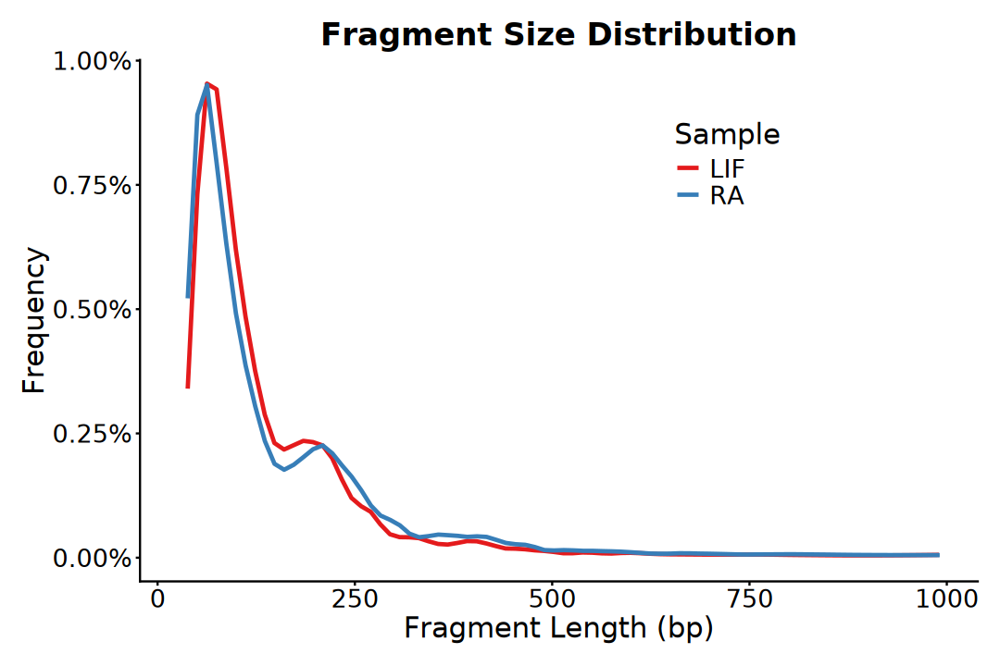

In [5]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(fragment_size, aes(x = Size, y = Freq, group = Sample)) +
    geom_smooth(
        aes(color = Treatment), formula = y ~ x, method = "loess", 
        na.rm = TRUE, se = FALSE, span = 0.1, linewidth = 1) +
    scale_y_continuous(
        limits = c(0, NA), labels = scales::percent_format()) +
    scale_color_brewer(
        palette = "Set1", labels = function(x) gsub("_", " ", x)) + 
    labs(
        title = "Fragment Size Distribution", color = "Sample",
        x = "Fragment Length (bp)", y = "Frequency") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        legend.position = "inside",
        legend.position.inside = c(0.7, 0.8),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

## 3). Fingerprints

> - Diaz, A., Nellore, A. & Song, J.S. CHANCE: comprehensive software for quality control and validation of ChIP-seq data. Genome Biol 13, R98 (2012). https://doi.org/10.1186/gb-2012-13-10-r98

In [6]:
marks <- c(
    "H3K4me3", "H3K4me1", "H3K27ac", "H3K122ac", 
    "H3K79me2", "H3K36me3", "H3K27me3", "H3K9me3")

# Cumulative Distribution Function
plot_df <- file.path(chipseq_dir, "01_stats", "fingerprint.tsv") |>
    read.table(
        header = TRUE, sep = "\t", check.names = FALSE, comment.char = "#") |>
    pivot_longer(
        cols = everything(), names_to = "Sample", values_to = "Counts") |>
    separate_wider_delim(
        cols = Sample, names = c("Cell", "Treatment", "Marks"),
        delim = "_", cols_remove = FALSE) |>
    mutate(
        Treatment = factor(Treatment, levels = c("LIF", "RA")),
        Marks = factor(Marks, levels = c(marks, "Input"))) |>
    arrange(Sample, Counts) |>
    group_by(Sample) |>
    mutate(
        cum_reads = cumsum(Counts),
        fraction_reads = cum_reads / last(cum_reads),
        fraction_bins = row_number() / n()) |>
    ungroup()

head(plot_df)

Cell,Treatment,Marks,Sample,Counts,cum_reads,fraction_reads,fraction_bins
<chr>,<fct>,<fct>,<chr>,<int>,<int>,<dbl>,<dbl>
mESC,LIF,H3K122ac,mESC_LIF_H3K122ac,0,0,0,2.155335e-06
mESC,LIF,H3K122ac,mESC_LIF_H3K122ac,0,0,0,4.310670e-06
mESC,LIF,H3K122ac,mESC_LIF_H3K122ac,0,0,0,6.466005e-06
mESC,LIF,H3K122ac,mESC_LIF_H3K122ac,0,0,0,8.621340e-06
mESC,LIF,H3K122ac,mESC_LIF_H3K122ac,0,0,0,1.077667e-05
mESC,LIF,H3K122ac,mESC_LIF_H3K122ac,0,0,0,1.293201e-05


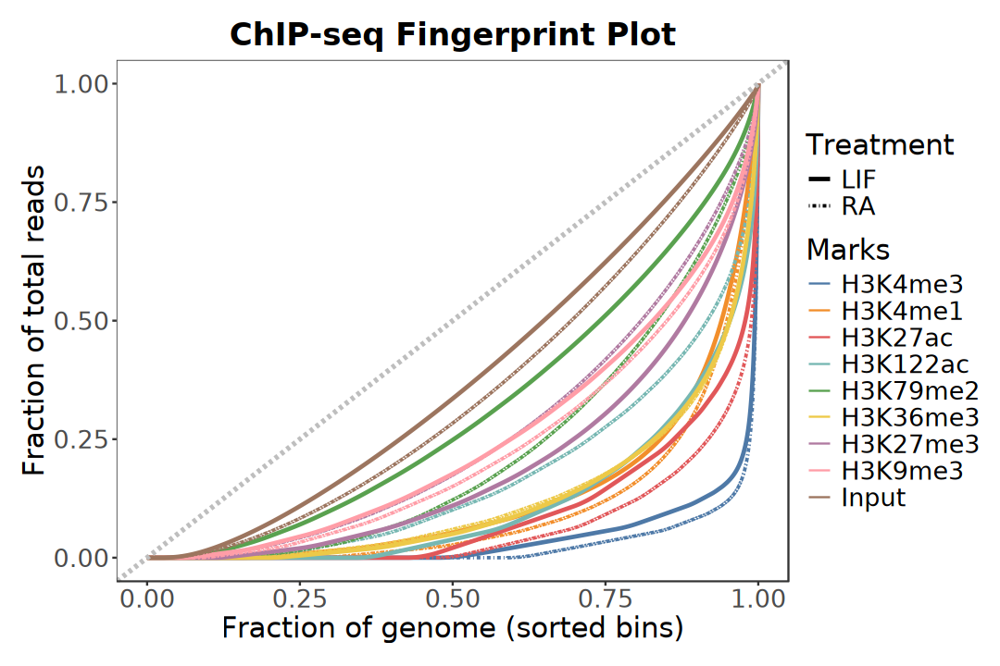

In [7]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = fraction_bins, y = fraction_reads)) +
    geom_line(
        aes(color = Marks, linetype = Treatment, linewidth = Treatment)) +
    geom_abline(
        slope = 1, intercept = 0, color = "gray", 
        linetype = "dashed", linewidth = 1.2) +
    # scale_color_discrete(palette = "Set1") + 
    ggthemes::scale_color_tableau(palette = "Tableau 10") + 
    scale_linetype_manual(
        values = c("LIF" = "solid", "RA" = "dotdash")) +
    scale_linewidth_manual(
        values = c("LIF" = 1, "RA" = 0.8)) +
    labs(
        title = "ChIP-seq Fingerprint Plot",
        x = "Fraction of genome (sorted bins)", 
        y = "Fraction of total reads") +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        panel.spacing.x = unit(0, "lines"),
        legend.position = "right",
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

## 4). TSS Enrichment Score

In [ ]:
compute_tss_score <- function(
    matrix_file, sample, bs = 10, verbose = TRUE) {

    mat <- matrix_file |> 
        read.table(header = FALSE, sep = "\t", skip = 3) |>
        as.matrix()

    profile <- colMeans(mat, na.rm = TRUE)
    nbins <- length(profile)
    flank_bins <- 100 / bs

    background <- c(
        profile[1:flank_bins], 
        profile[(nbins - flank_bins + 1):nbins]) |> mean()

    norm_profile <- profile / background

    center_bin <- floor(nbins / 2)
    tss_score <- mean(norm_profile[center_bin:(center_bin + 1)])
    if (verbose) {
        message(sample, " TSS Enrichment Score: ", round(tss_score, 2))
    }

    data.frame(
        Position = seq(-2000, 1990, by = bs),
        Signal = profile, 
        Sample = sample, 
        TSS_Score = tss_score, 
        Label = paste0(sample, " (Score: ", round(tss_score, 2), ")"))
}

In [9]:
atac_matrix_files <- file.path(atacseq_dir, "08_deeptools") |>
    list.files(pattern = "\\.TSS\\.tsv$", full.names = TRUE) |>
    set_names(~ sub("(.*)\\.TSS\\.tsv$", "\\1", basename(.x)))

chip_matrix_files <- file.path(chipseq_dir, "08_deeptools") |>
    list.files(pattern = "\\.TSS\\.tsv$", full.names = TRUE) |>
    set_names(~ sub("(.*)\\.TSS\\.tsv$", "\\1", basename(.x)))

matrix_files <- c(atac_matrix_files, chip_matrix_files)

In [10]:
profiles_list <- imap(matrix_files, compute_tss_score, verbose = FALSE)

In [11]:
marks <- c("ATAC", marks, "Input")

profile_df <- do.call(rbind, profiles_list) |>
    separate(
        Sample, into = c("Cell", "Treatment", "Marks"),
        sep = "_", remove = FALSE) |>
    mutate(
        Treatment = factor(Treatment, levels = c("LIF", "RA")),
        Marks = factor(Marks, levels = marks)) |>
    arrange(Treatment, Marks) |>
    mutate(Label = forcats::fct_inorder(as.character(Label)))

head(profile_df)

,Position,Signal,Sample,Cell,Treatment,Marks,TSS_Score,Label
,<dbl>,<dbl>,<chr>,<chr>,<fct>,<fct>,<dbl>,<fct>
mESC_LIF_ATAC.V1,-2000,123.1760,mESC_LIF_ATAC,mESC,LIF,ATAC,13.58707,mESC_LIF_ATAC (Score: 13.59)
mESC_LIF_ATAC.V2,-1990,124.0149,mESC_LIF_ATAC,mESC,LIF,ATAC,13.58707,mESC_LIF_ATAC (Score: 13.59)
mESC_LIF_ATAC.V3,-1980,124.0383,mESC_LIF_ATAC,mESC,LIF,ATAC,13.58707,mESC_LIF_ATAC (Score: 13.59)
mESC_LIF_ATAC.V4,-1970,123.6838,mESC_LIF_ATAC,mESC,LIF,ATAC,13.58707,mESC_LIF_ATAC (Score: 13.59)
mESC_LIF_ATAC.V5,-1960,122.4179,mESC_LIF_ATAC,mESC,LIF,ATAC,13.58707,mESC_LIF_ATAC (Score: 13.59)
mESC_LIF_ATAC.V6,-1950,122.2158,mESC_LIF_ATAC,mESC,LIF,ATAC,13.58707,mESC_LIF_ATAC (Score: 13.59)


In [12]:
# Automatically generate a corresponding marks color for every label.
unique_labels <- levels(profile_df$Label)
associated_antibodies <- sub(
    "^mESC_[^_]+_([^\\s(]+)\\s+\\(Score:.*\\)", "\\1", unique_labels)
associated_antibodies <- factor(associated_antibodies, levels = marks)

# marks_colors <- viridis::viridis(nlevels(associated_antibodies))
# marks_colors <- RColorBrewer::brewer.pal(
#     nlevels(associated_antibodies), "Set3")
marks_colors <- ggthemes::tableau_color_pal(
    palette = "Tableau 10")(nlevels(associated_antibodies))

label_color_mapping <- marks_colors[as.numeric(associated_antibodies)]
names(label_color_mapping) <- unique_labels

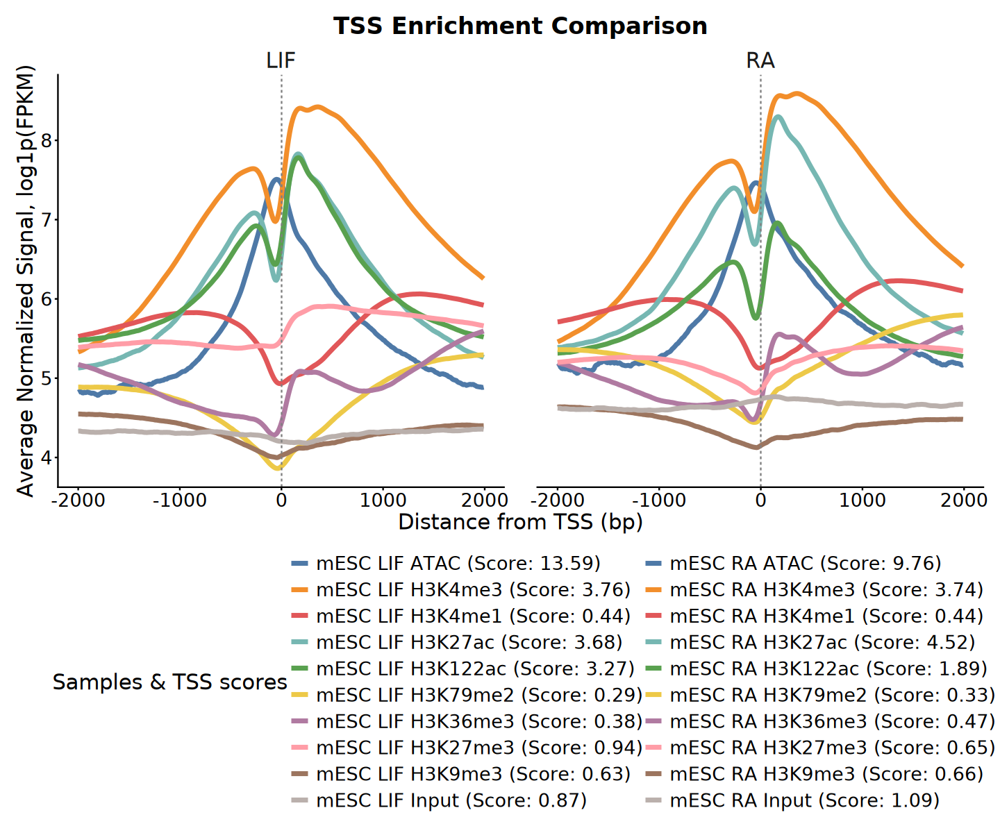

In [ ]:
options(repr.plot.width = 12, repr.plot.height = 10)

ggplot(profile_df, aes(x = Position, y = log1p(Signal))) +
    geom_line(aes(color = Label), linewidth = 1.5) +
    geom_vline(
        xintercept = 0, linetype = "dashed", color = "gray50") +
    facet_wrap(~ Treatment, ncol = 2) +
    scale_color_manual(
        values = label_color_mapping,
        labels = function(x) gsub("_", " ", x)
    ) +
    guides(color = guide_legend(ncol = 2)) +
    labs(
        title = "TSS Enrichment Comparison",
        color = "Samples & TSS scores",
        x = "Distance from TSS (bp)",
        y = "Average Normalized Signal, log1p(FPKM)") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        panel.spacing = unit(2, "lines"), 
        strip.placement = "outside",
        strip.background = element_blank(),
        strip.text = element_text(size = 18),
        legend.position = "bottom",
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

# 2. Data Import

In [14]:
marks <- c(
    "H3K4me3", "H3K4me1", "H3K27ac", "H3K122ac", 
    "H3K79me2", "H3K36me3", "H3K27me3", "H3K9me3")

broad_marks <- c("H3K36me3", "H3K79me2", "H3K27me3", "H3K9me3")

sample_order <- c("ATAC", marks, "Input")

sample_order

[1] "ATAC"     "H3K4me3"  "H3K4me1"  "H3K27ac"  "H3K122ac" "H3K79me2"
 [7] "H3K36me3" "H3K27me3" "H3K9me3"  "Input"

## 1). Import narrowPeak

In [ ]:
# Load macs2 narrowPeak file as GRanges
load_narrowPeak <- function(
    file, format = "auto", keepStandardChr = TRUE, 
    dropSex = TRUE, dropMito = TRUE, blacklist = NULL) {

    if (format == "auto") {
        if (grepl("\\.narrowPeak$", file)) {
            format <- "narrowPeak"
        } else if (grepl("\\.broadPeak$", file)) {
            format <- "broadPeak"
        } else if (grepl("\\.gappedPeak$", file)) {
            format <- "gappedPeak"
        } else {
            format <- "BED"
        }
    }

    gr <- rtracklayer::import(file, format = format)

    # ---- Keep only standard chromosomes (optional) ----
    if (keepStandardChr) {
        gr <- GenomeInfoDb::keepStandardChromosomes(
            gr, pruning.mode = "coarse")
    }

    # ---- Remove sex chromosomes (optional) ----
    if (dropSex) {
        gr <- GenomeInfoDb::dropSeqlevels(
            gr, c("chrX", "chrY"), pruning.mode = "coarse")
    }

    # ---- Remove mitochondrial DNA (optional) ----
    if (dropMito) {
        gr <- GenomeInfoDb::dropSeqlevels(
            gr, c("chrM", "M", "MT"), pruning.mode = "coarse")
    }

    # ---- Remove blacklist region (optional) ----
    if (!is.null(blacklist)) {
        if (is.character(blacklist)) {
            blacklist <- rtracklayer::import(blacklist)
        }
        gr <- IRanges::subsetByOverlaps(gr, blacklist, invert = TRUE)
    }

    return(gr)
}

In [ ]:
atac_peaks_files <- file.path(atacseq_dir, "05_peaks") |>
    list.files(pattern = "_peaks\\.narrowPeak$", full.names = TRUE) |>
    set_names(~ sub("(.*)_peaks\\.narrowPeak$", "\\1", basename(.x)))

In [ ]:
chip_peaks_files <- marks |> 
    map(\(mark) {
        if (mark %in% broad_marks) {
            folder <- "05_peaks_broad"
            pattern <- paste0("_", mark, "_peaks\\.broadPeak$")
        } else {
            folder <- "05_peaks"
            pattern <- paste0("_", mark, "_peaks\\.narrowPeak$")
        }

        full_path <- file.path(chipseq_dir, folder) |>
            list.files(pattern = pattern, full.names = TRUE)

        return(full_path)}) |> flatten_chr()

names(chip_peaks_files) <- chip_peaks_files |> basename() |> 
    sub("_peaks\\.(narrowPeak|broadPeak)$", "", x = _)

# chip_peaks_files <- file.path(chipseq_dir, "05_peaks") |>
#     list.files(pattern = "peaks\\.narrowPeak$") |>
#     set_names(~ sub("(.*)_peaks\\.narrowPeak$", "\\1", .x))

In [18]:
peaks_files <- c(atac_peaks_files, chip_peaks_files)
peaks_files <- peaks_files[grepl("LIF", names(peaks_files))]
names(peaks_files) <- sub("^[^_]+_LIF_", "", names(peaks_files))

paste(names(peaks_files), basename(peaks_files), sep = ": ") |> cat(sep = "\n")

ATAC: mESC_LIF_ATAC_peaks.narrowPeak
H3K4me3: mESC_LIF_H3K4me3_peaks.narrowPeak
H3K4me1: mESC_LIF_H3K4me1_peaks.narrowPeak
H3K27ac: mESC_LIF_H3K27ac_peaks.narrowPeak
H3K122ac: mESC_LIF_H3K122ac_peaks.narrowPeak
H3K79me2: mESC_LIF_H3K79me2_peaks.broadPeak
H3K36me3: mESC_LIF_H3K36me3_peaks.broadPeak
H3K27me3: mESC_LIF_H3K27me3_peaks.broadPeak
H3K9me3: mESC_LIF_H3K9me3_peaks.broadPeak


In [ ]:
peaks_list <- lapply(
    peaks_files, load_narrowPeak, 
    dropSex = FALSE, blacklist = blacklist_file)
peaks_list <- peaks_list[sample_order[-length(sample_order)]]

In [20]:
peaks_list[1]

$ATAC
GRanges object with 109058 ranges and 6 metadata columns:
           seqnames            ranges strand |                   name     score
              <Rle>         <IRanges>  <Rle> |            <character> <numeric>
       [1]     chr1   3062773-3063070      * |  mESC_LIF_ATAC_peak_49       423
       [2]     chr1   3191360-3191826      * |  mESC_LIF_ATAC_peak_50       192
       [3]     chr1   3263775-3263941      * |  mESC_LIF_ATAC_peak_51       219
       [4]     chr1   3343574-3343811      * |  mESC_LIF_ATAC_peak_52       313
       [5]     chr1   3344201-3344399      * |  mESC_LIF_ATAC_peak_53       137
       ...      ...               ...    ... .                    ...       ...
  [109054]     chrY   1959556-1959772      * | mESC_LIF_ATAC_peak_1..        60
  [109055]     chrY   6158748-6158891      * | mESC_LIF_ATAC_peak_1..       116
  [109056]     chrY   6168272-6168663      * | mESC_LIF_ATAC_peak_1..        50
  [109057]     chrY   9836987-9837252      * | mESC_LIF_

## 2). Import bigwig

In [ ]:
# Load bigwig (bw) file as GRanges
load_bigwig <- function(
    file, keepStandardChr = TRUE, dropSex = TRUE, dropMito = TRUE, 
    blacklist = NULL) {

    gr <- rtracklayer::import.bw(file)

    # ---- Keep only standard chromosomes (optional) ----
    if (keepStandardChr) {
        gr <- GenomeInfoDb::keepStandardChromosomes(
            gr, pruning.mode = "coarse")
    }

    # ---- Remove sex chromosomes (optional) ----
    if (dropSex) {
        gr <- GenomeInfoDb::dropSeqlevels(
            gr, c("chrX", "chrY", "X", "Y"), pruning.mode = "coarse")
    }

    # ---- Remove mitochondrial DNA (optional) ----
    if (dropMito) {
        gr <- GenomeInfoDb::dropSeqlevels(
            gr, c("chrM", "M", "MT"), pruning.mode = "coarse")
    }

    # ---- Remove blacklist regions (optional) ----
    if (!is.null(blacklist)) {
        if (is.character(blacklist)) {
            blacklist <- rtracklayer::import(blacklist)
        }
        gr <- IRanges::subsetByOverlaps(gr, blacklist, invert = TRUE)
    }

    return(gr)
}

In [ ]:
atac_signals_files <- file.path(atacseq_dir, "07_bigwig") |>
    list.files(pattern = "\\.bin10.bw$", full.names = TRUE) |>
    set_names(~ sub("(.*)\\.bin10.bw$", "\\1", basename(.x))) |>
    (\(files) files[!grepl("shifted", files)])()

chip_signals_files <- file.path(chipseq_dir, "07_bigwig") |>
    list.files(pattern = "\\.bin10.bw$", full.names = TRUE) |>
    set_names(~ sub("(.*)\\.bin10.bw$", "\\1", basename(.x)))

signals_files <- c(atac_signals_files, chip_signals_files)
signals_files <- signals_files[grepl("LIF", names(signals_files))]
names(signals_files) <- sub("^[^_]+_LIF_", "", names(signals_files))

paste(names(signals_files), basename(signals_files), sep = ": ") |> 
    cat(sep = "\n")

ATAC: mESC_LIF_ATAC.bin10.bw
H3K122ac: mESC_LIF_H3K122ac.bin10.bw
H3K27ac: mESC_LIF_H3K27ac.bin10.bw
H3K27me3: mESC_LIF_H3K27me3.bin10.bw
H3K36me3: mESC_LIF_H3K36me3.bin10.bw
H3K4me1: mESC_LIF_H3K4me1.bin10.bw
H3K4me3: mESC_LIF_H3K4me3.bin10.bw
H3K79me2: mESC_LIF_H3K79me2.bin10.bw
H3K9me3: mESC_LIF_H3K9me3.bin10.bw
Input: mESC_LIF_Input.bin10.bw


In [ ]:
signals_list <- lapply(
    signals_files, load_bigwig, dropSex = FALSE, blacklist = blacklist_file)
signals_list <- signals_list[sample_order]

In [24]:
signals_list[1]

$ATAC
GRanges object with 19205740 ranges and 1 metadata column:
             seqnames            ranges strand |     score
                <Rle>         <IRanges>  <Rle> | <numeric>
         [1]     chr1         1-3003290      * |   0.00000
         [2]     chr1   3003291-3003410      * |   5.40854
         [3]     chr1   3003411-3003450      * |  10.81710
         [4]     chr1   3003451-3003470      * |  16.22560
         [5]     chr1   3003471-3003510      * |  10.81710
         ...      ...               ...    ... .       ...
  [19205736]     chrY 41157671-41158310      * |   0.00000
  [19205737]     chrY 41158311-41158410      * |   5.40854
  [19205738]     chrY 41158411-41158450      * |   0.00000
  [19205739]     chrY 41158451-41158680      * |   5.40854
  [19205740]     chrY 41158681-41159190      * |   0.00000
  -------
  seqinfo: 21 sequences from an unspecified genome


# 4. Histons Pattern

## 1). Number of Peaks

In [25]:
coldata <- tibble(sample = names(peaks_list)) |>
    mutate(
        Cell = "mESC", 
        Marks = factor(sample, levels = c("ATAC", marks)),
        Number = lengths(peaks_list)) |>
    arrange(Marks) |> 
    column_to_rownames("sample")

coldata

,Cell,Marks,Number
,<chr>,<fct>,<int>
ATAC,mESC,ATAC,109058
H3K4me3,mESC,H3K4me3,43494
H3K4me1,mESC,H3K4me1,131355
H3K27ac,mESC,H3K27ac,44684
H3K122ac,mESC,H3K122ac,85005
H3K79me2,mESC,H3K79me2,23115
H3K36me3,mESC,H3K36me3,55093
H3K27me3,mESC,H3K27me3,122095
H3K9me3,mESC,H3K9me3,55863


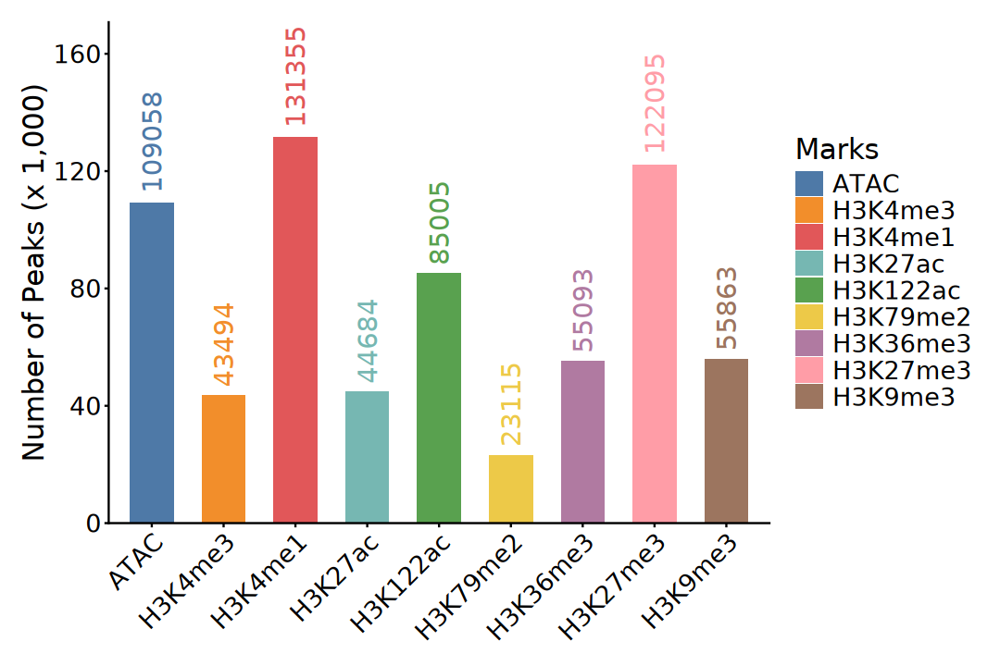

In [26]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(coldata, aes(Marks, Number)) +
    geom_bar(
        aes(fill = Marks), stat = "identity", width = 0.6) +
    geom_text(
        aes(color = Marks, label = Number), 
        angle = 90, hjust = -0.1, vjust = 0.5, size = 6) +
    scale_y_continuous(
        labels = function(x) x / 1000, 
        expand = expansion(mult = c(0, 0.3))) + 
    ggthemes::scale_color_tableau(palette = "Tableau 10") + 
    ggthemes::scale_fill_tableau(palette = "Tableau 10") + 
    labs(x = NULL, y = "Number of Peaks (x 1,000)") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        legend.position = "right",
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text.x = element_text(size = 16, angle = 45, hjust = 1),
        axis.text.y = element_text(size = 16))

## 2). Peaks Annotation

In [27]:
# load reference gene anntotion
gtf <- import(gtf_file) |> 
    BRGenomics::tidyChromosomes(
        keep.X = TRUE, keep.Y = TRUE, keep.M = FALSE)

standard_chromosome <- seqinfo(gtf) |> seqnames()

In [28]:
# txdb <- txdbmaker::makeTxDbFromGFF(
#     gtf_file, dataSource = "Gencode", 
#     organism = "Mus musculus", taxonomyId = 10090, 
#     metadata = data.frame(
#         name = c("Genome", "Gencode Release"), 
#         value = c("mm10", "vM23")))

txdb <- txdbmaker::makeTxDbFromGRanges(
    gtf, drop.stop.codons = TRUE, taxonomyId = 10090, 
    metadata = data.frame(
        name = c("Genome", "Gencode Release"),
        value = c("mm10", "vM23")))

Warning message in .get_cds_IDX(mcols0$type, mcols0$phase):
“The "phase" metadata column contains non-NA values for features of type
  stop_codon. This information was ignored.”
Warning message in .makeTxDb_normarg_chrominfo(chrominfo):
“genome version information is not available for this TxDb object”


In [29]:
blacklist <- rtracklayer::import(blacklist_file)
blacklist

GRanges object with 3435 ranges and 1 metadata column:
         seqnames            ranges strand |               name
            <Rle>         <IRanges>  <Rle> |        <character>
     [1]    chr10         1-3135400      * | High Signal Region
     [2]    chr10   3218901-3276600      * |    Low Mappability
     [3]    chr10   3576901-3627700      * |    Low Mappability
     [4]    chr10   4191101-4197600      * |    Low Mappability
     [5]    chr10   4613501-4615400      * | High Signal Region
     ...      ...               ...    ... .                ...
  [3431]     chrY   6530201-6663200      * | High Signal Region
  [3432]     chrY   6760201-6835800      * | High Signal Region
  [3433]     chrY   6984101-8985400      * | High Signal Region
  [3434]     chrY 10638501-41003800      * | High Signal Region
  [3435]     chrY 41159201-91744600      * | High Signal Region
  -------
  seqinfo: 21 sequences from an unspecified genome; no seqlengths

### a). ChIPseeker

In [30]:
suppressPackageStartupMessages(library(ChIPseeker))

In [ ]:
peaks_anno_list <- lapply(
    peaks_list, annotatePeak, tssRegion = c(-2000, 500), 
    TxDb = txdb, level = "gene", verbose = FALSE,
    genomicAnnotationPriority = c("Promoter", "Exon", "Intron", "Intergenic"))

>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...


Warning message:
“`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the ChIPseeker package.
  Please report the issue at <https://github.com/YuLab-SMU/ChIPseeker/issues>.”


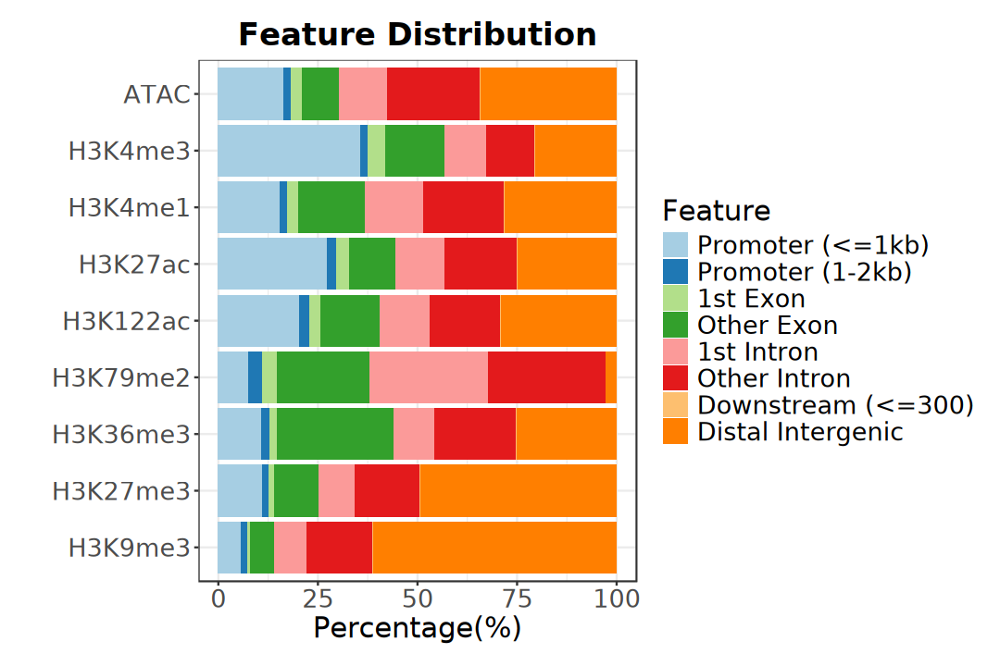

In [32]:
options(repr.plot.width = 9, repr.plot.height = 6)

plotAnnoBar(peaks_anno_list) +
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        legend.position = "right", 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

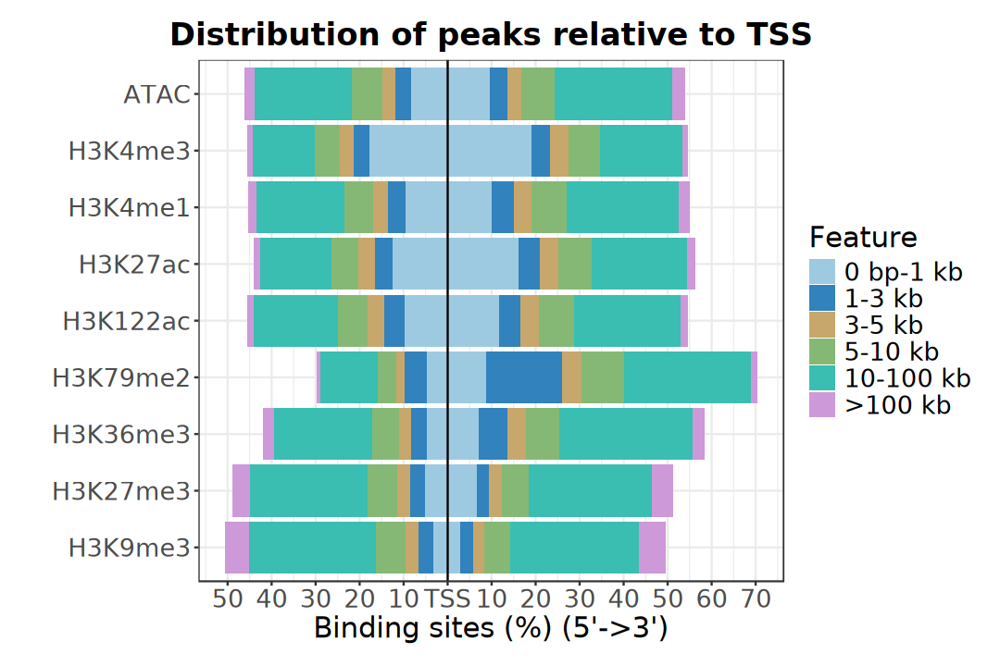

In [33]:
options(repr.plot.width = 9, repr.plot.height = 6)

plotDistToTSS(peaks_anno_list, title = "Distribution of peaks relative to TSS") +
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        legend.position = "right", 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [ ]:
anno_stats <- lapply(peaks_anno_list, function(anno) {
    anno@annoStat |>
    mutate(
        MergedFeature = case_when(
            Feature %in% c(
                "Promoter (<=1kb)", "Promoter (1-2kb)") ~ "Promoter",
            Feature %in% c(
                "1st Exon", "Other Exon") ~ "Exon",
            Feature %in% c(
                "1st Intron", "Other Intron") ~ "Intron",
            Feature %in% c(
                "Downstream (<=300)", "Distal Intergenic") ~ "Intergenic",
            TRUE ~ as.character(Feature))) |>
    group_by(MergedFeature) |> 
    summarise(Frequency = sum(Frequency)) |>
    ungroup()
})

In [35]:
anno_stats_combined <- bind_rows(anno_stats, .id = "Sample") |>
    mutate(
        Sample = factor(Sample, levels = rev(sample_order)),
        MergedFeature = MergedFeature |>
            factor(levels = c("Promoter", "Exon", "Intron", "Intergenic")))

head(anno_stats_combined)

Sample,MergedFeature,Frequency
<fct>,<fct>,<dbl>
ATAC,Exon,12.18709
ATAC,Intergenic,34.18456
ATAC,Intron,35.41877
ATAC,Promoter,18.20958
H3K4me3,Exon,19.17276
H3K4me3,Intergenic,20.51088


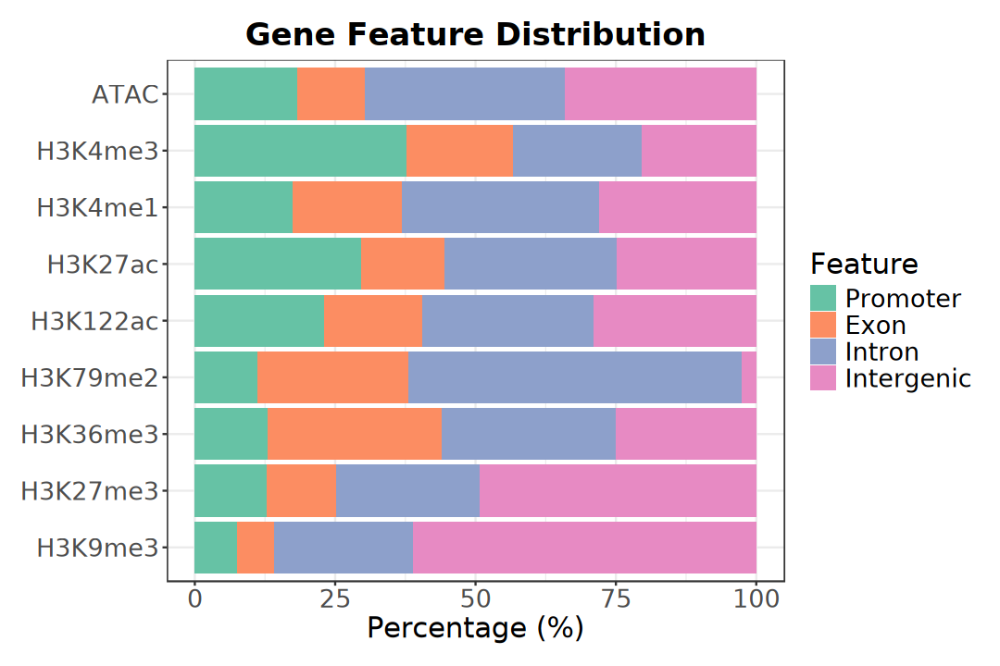

In [36]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(anno_stats_combined, aes(x = Sample, y = Frequency)) +
    geom_bar(
        aes(fill = MergedFeature), stat = "identity", 
        position = position_stack(reverse = TRUE)) +
    scale_fill_brewer(palette = "Set2") + 
    labs(
        title = "Gene Feature Distribution",
        x = NULL, y = "Percentage (%)", fill = "Feature") +
    coord_flip() +
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.position = "right", 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

### b). ChIPpeakAnno

In [37]:
suppressPackageStartupMessages(library(ChIPpeakAnno))

In [38]:
peaks_anno_list <- lapply(
    peaks_list, assignChromosomeRegion, 
    TxDb = txdb, nucleotideLevel = FALSE,
    proximal.promoter.cutoff = c(upstream = 2000, downstream = 500),
    immediate.downstream.cutoff = c(upstream = 0, downstream = 0),
    precedence = c(
        "Promoters", "fiveUTRs", "threeUTRs", "Exons", 
        "Introns", "immediateDownstream"))

In [ ]:
anno_stats <- lapply(peaks_anno_list, function(anno) {
    anno$percentage |>
        as.data.frame() |>
        rownames_to_column(var = "Feature") |>
        mutate(
            MergedFeature = case_when(
                Feature %in% c(
                    "Promoters") ~ "Promoter",
                Feature %in% c(
                    "Exons", "fiveUTRs", "threeUTRs") ~ "Exon",
                Feature %in% c(
                    "Introns") ~ "Intron",
                Feature %in% c(
                    "immediateDownstream", "Intergenic.Region") ~ "Intergenic",
                TRUE ~ as.character(Feature))) |>
        group_by(MergedFeature) |> 
        summarise(Frequency = sum(`anno$percentage`)) |>
        ungroup()
})

In [40]:
anno_stats_combined <- bind_rows(anno_stats, .id = "Sample") |>
    mutate(
        Sample = factor(Sample, levels = rev(sample_order)),
        MergedFeature = MergedFeature |>
            factor(levels = c("Promoter", "Exon", "Intron", "Intergenic")))

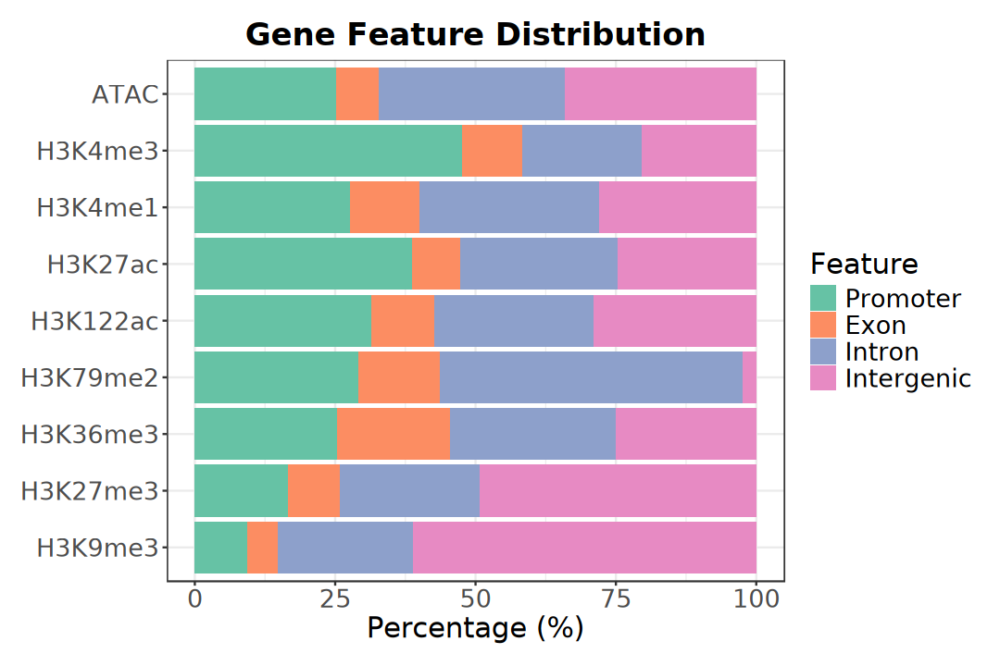

In [41]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(anno_stats_combined, aes(x = Sample, y = Frequency)) +
    geom_bar(
        aes(fill = MergedFeature), stat = "identity", 
        position = position_stack(reverse = TRUE)) +
    scale_fill_brewer(palette = "Set2") + 
    labs(
        title = "Gene Feature Distribution",
        x = NULL, y = "Percentage (%)", fill = "Feature") +
    coord_flip() +
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.position = "right", 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

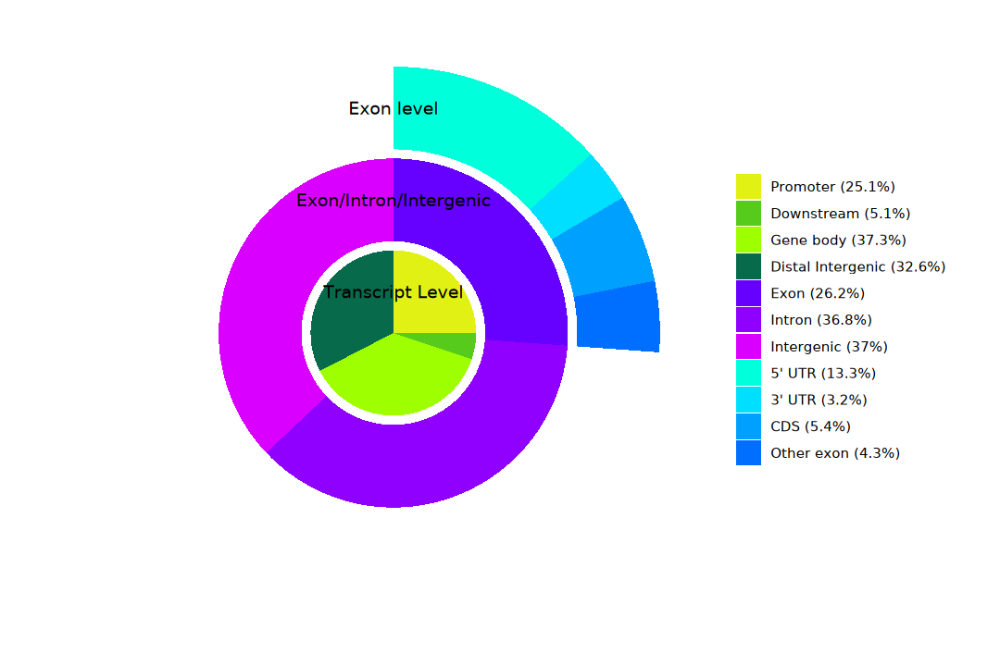

In [42]:
options(repr.plot.width = 9, repr.plot.height = 6)

genomicElementDistribution(
    peaks_list[[1]], TxDb = txdb, 
    promoterRegion = c(upstream = 2000, downstream = 500), 
    geneDownstream = c(upstream = 0, downstream = 1000))

### c). Manual

In [43]:
feature_list <- list(
    TSS = gtf[gtf$type == "gene", ] |> 
        promoters(upstream = 0, downstream = 1),
    Promoter = gtf[gtf$type == "gene", ] |>
        promoters(upstream = 2000, downstream = 500),
    Exon = gtf[gtf$type == "exon", ],
    Intron = GenomicFeatures::intronsByTranscript(
        txdb, use.names = TRUE) |> 
        unlist()
)

In [ ]:
# ------------------------------------------------------------------------------
# Function: annotate_peaks_with_genomic_features
#
# Description:
# This function performs hierarchical genomic annotation of peak regions 
# (GRanges) based on predefined genomic feature categories and computes the 
# strand-aware signed distance to the nearest transcription start site (TSS).
# ------------------------------------------------------------------------------

annotate_peaks_with_genomic_features <- function(
    peaks, featureList, sameStrand = FALSE, 
    precedence = c("Promoter", "Exon", "Intron", "Intergenic")) {

    peaks$Annotation <- "Intergenic"
    precedence <- precedence[precedence != "Intergenic"]

    for (feature in rev(precedence)) {
        if (!feature %in% names(featureList)) next
        hits <- overlapsAny(
            peaks, featureList[[feature]], ignore.strand = !sameStrand)
        peaks$Annotation[hits] <- feature
    }

    idx <- nearest(
        peaks, featureList[["TSS"]], ignore.strand = !sameStrand)

    peak_center <- start(peaks) + 
        ifelse(
            "peak" %in% colnames(mcols(peaks)), 
            peaks$peak, round(width(peaks)/2))

    tss_coord <- start(featureList[["TSS"]])[idx]
    tss_str <- as.vector(strand(featureList[["TSS"]]))[idx]

    dist <- peak_center - tss_coord
    dist[tss_str == "-"] <- -dist[tss_str == "-"]
    dist[is.na(idx)] <- NA_integer_

    peaks$SignedDistToTSS <- dist

    return(peaks)
}

In [45]:
peaks_anno_list <- lapply(
    peaks_list, annotate_peaks_with_genomic_features, 
    featureList = feature_list)

In [46]:
anno_stats <- imap_dfr(peaks_anno_list, function(gr, sample_name) {
    gr$Annotation |> table() |>
        as.data.frame() |>
        mutate(
            MergedFeature = Var1, 
            Frequency = Freq,
            Sample = sample_name) |>
        select(MergedFeature, Frequency, Sample)
})

In [47]:
anno_stats_combined <- bind_rows(anno_stats) |>
    mutate(
        Sample = factor(Sample, levels = rev(sample_order)),
        MergedFeature = MergedFeature |>
            factor(levels = c("Promoter", "Exon", "Intron", "Intergenic")))

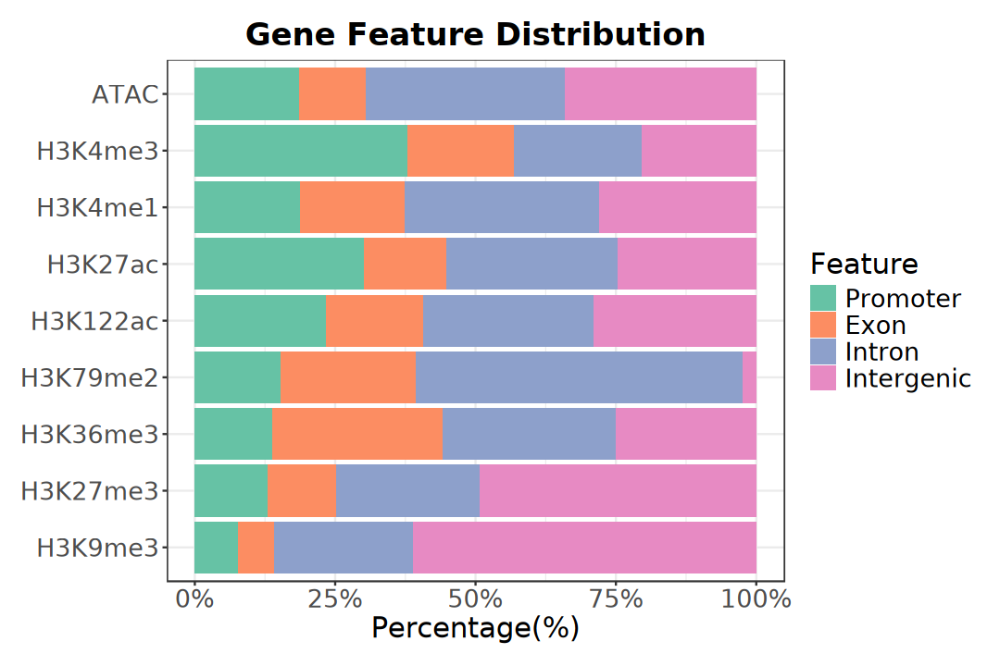

In [48]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(anno_stats_combined, aes(x = Sample, y = Frequency)) +
    geom_bar(
        aes(fill = MergedFeature), stat = "identity", 
        position = position_fill(reverse = TRUE)) +
    scale_y_continuous(labels = scales::percent_format()) + 
    scale_fill_brewer(palette = "Set2") + 
    labs(
        title = "Gene Feature Distribution",
        x = NULL, y = "Percentage(%)", fill = "Feature") +
    coord_flip() +
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.position = "right", 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [ ]:
combined_df <- imap_dfr(peaks_anno_list, function(gr, sample_name) {
    df <- as.data.frame(gr)
    df$Sample <- sample_name
    return(df)
})

plot_df <- combined_df |>
    mutate(distance = abs(SignedDistToTSS)) |>
    mutate(Group = case_when(
        distance <= 1000 ~ "<= 1kb",
        distance > 1000 & distance <= 3000 ~ "1 - 3kb",
        distance > 3000 & distance <= 10000 ~ "3 - 10kb",
        distance > 10000 ~ "> 10kb")) |>
    mutate(Group = factor(
        Group, levels = c(
            "<= 1kb", "1 - 3kb", "3 - 10kb", "> 10kb"))) |>
    group_by(Sample, Group) |>
    tally() |>
    mutate(Percentage = n / sum(n) * 100)

head(plot_df)

Sample,Dist_Group,n,Percentage
<chr>,<fct>,<int>,<dbl>
ATAC,<= 1kb,18485,16.949696
ATAC,1 - 3kb,8962,8.217646
ATAC,3 - 10kb,22594,20.717416
ATAC,> 10kb,59017,54.115241
H3K122ac,<= 1kb,13832,16.271984
H3K122ac,1 - 3kb,10460,12.305159


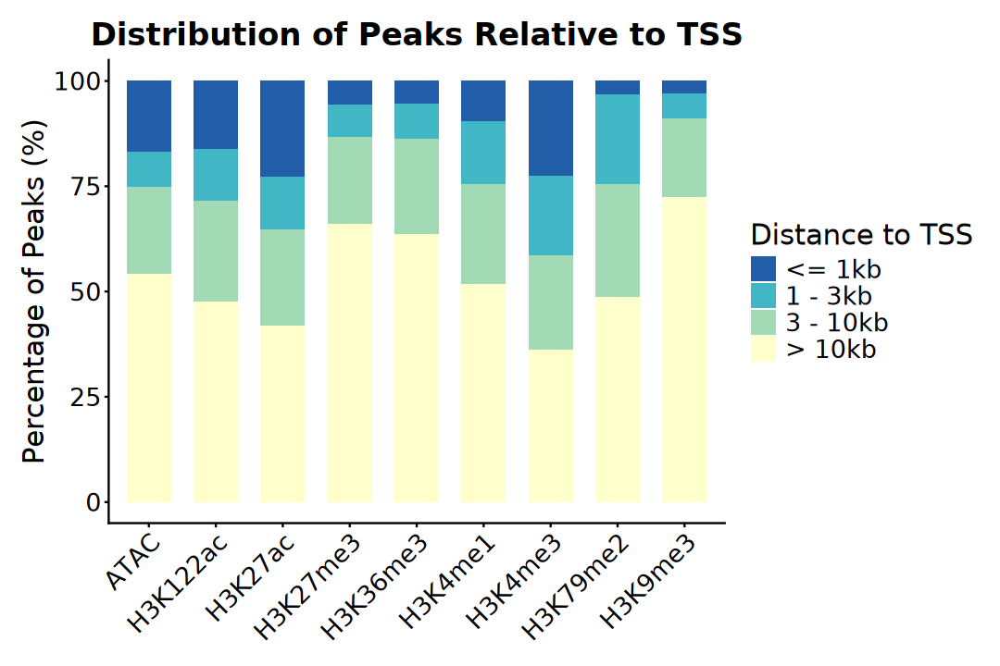

In [ ]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = Sample, y = Percentage, fill = Group)) +
     geom_bar(stat = "identity", position = "stack", width = 0.65) +
     scale_fill_brewer(palette = "YlGnBu", direction = -1) + 
     labs(
          title = "Distribution of Peaks Relative to TSS",
          x = NULL, y = "Percentage of Peaks (%)",
          fill = "Distance to TSS") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.position = "right",
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text.x = element_text(size = 16, angle = 45, hjust = 1),
        axis.text.y = element_text(size = 16))

## 3). Metagene Profile (Peaks)

In [51]:
GENES <- gtf |> subset(
    type == "gene" & gene_type == "protein_coding", 
    select = c("gene_id", "gene_name", "gene_type")
)

### a). EnrichedHeatmap

In [52]:
suppressPackageStartupMessages(library(circlize))
suppressPackageStartupMessages(library(EnrichedHeatmap))

In [53]:
# ~ 5 minutes
peaks_gene_mat_list <- lapply(
    peaks_list, normalizeToMatrix, GENES, 
    mean_mode = "coverage", extend = 2000, w = 50, 
    background = 0, target_ratio = 0.4)

In [ ]:
base_colors <- ggthemes::tableau_color_pal("Tableau 10")(
    length(peaks_gene_mat_list)) |> 
    setNames(names(peaks_gene_mat_list))

col_funs <- lapply(names(peaks_gene_mat_list), function(mark) {
    unname(c("#ffffff", base_colors[mark]))
})

names(col_funs) <- names(peaks_gene_mat_list)

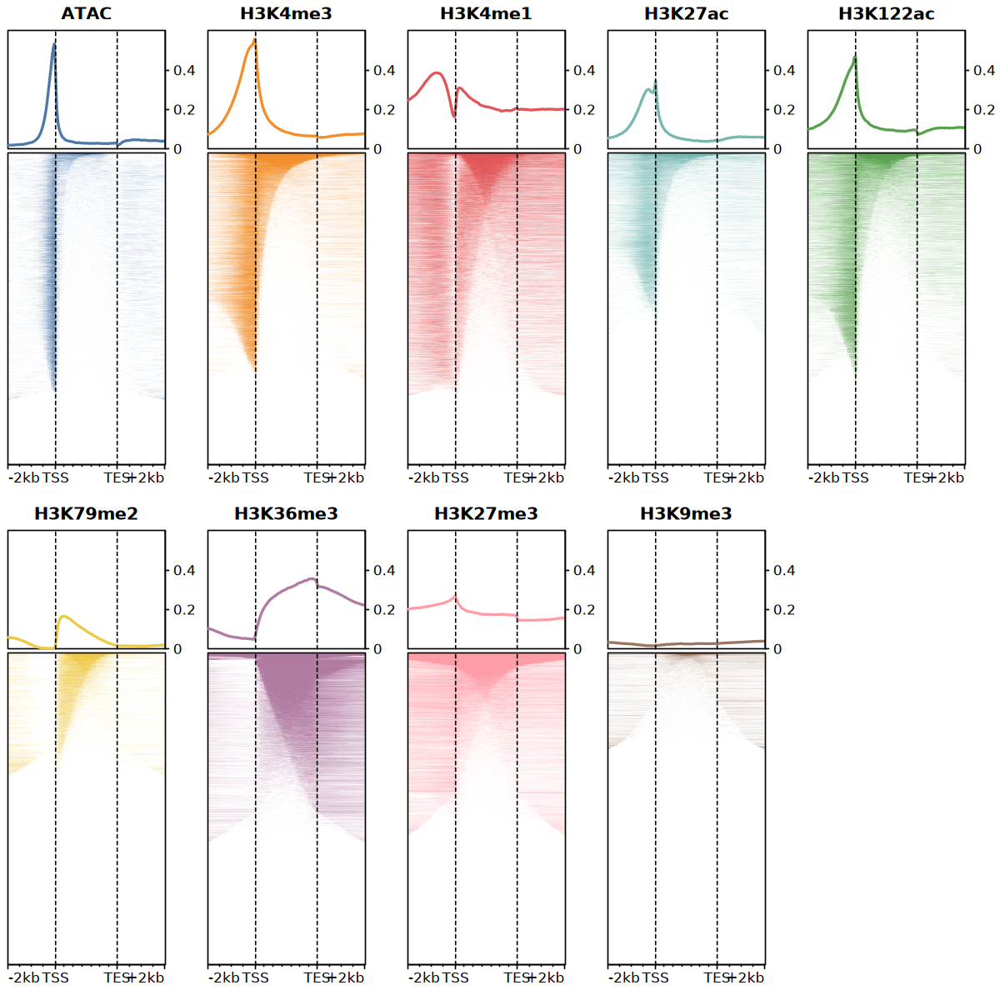

In [55]:
# ==============================================================================
# ⚠️ WARNING / IMPORTANT NOTE:
# With the current settings, the row order (gene/peak order) across different 
# heatmaps is INCONSISTENT. Each heatmap calculates its own hierarchical 
# clustering independently based on its input matrix. If you want to visually 
# compare rows across different groups, you must enforce a unified row order 
# by setting 'cluster_rows = FALSE' and providing a fixed 'row_order'.
# ==============================================================================
options(repr.plot.width = 10, repr.plot.height = 10)

# Create a new blank canvas
grid.newpage()
# Initialize a grid layout with 2 rows and 5 columns
pushViewport(viewport(layout = grid.layout(2, 5)))

for (i in seq_along(peaks_gene_mat_list)) {
    mark_name <- names(peaks_gene_mat_list)[i]

    # Enter the designated grid slot (viewport)
    row_idx <- if (i <= 5) 1 else 2
    col_idx <- if (i <= 5) i else i - 5
    pushViewport(viewport(layout.pos.row = row_idx, layout.pos.col = col_idx))
    
    # Construct the individual EnrichedHeatmap object
    ht <- EnrichedHeatmap(
        peaks_gene_mat_list[[i]], 
        name = mark_name, 
        column_title = mark_name, 
        column_title_gp = gpar(fontsize = 12, fontface = "bold"),
        col = col_funs[[mark_name]], 
        top_annotation = HeatmapAnnotation(
            lines = anno_enriched(
                gp = gpar(lwd = 2, col = base_colors[mark_name]), 
                ylim = c(0, 0.6), 
                axis_param = list(gp = gpar(fontsize = 10))),
            height = unit(3, "cm"), show_legend = FALSE), 
        axis_name = c("-2kb", "TSS", "TES", "+2kb"),
        axis_name_gp = gpar(fontsize = 10),
        show_heatmap_legend = FALSE, 
        show_row_names = FALSE,
        width = unit(4, "cm"),
        use_raster = TRUE)
    
    # Render the heatmap inside the current viewport
    draw(ht, newpage = FALSE)
    # Exit the current grid slot viewport
    popViewport()
}
# Exit the main grid layout viewport
popViewport()

In [56]:
position_levels <- c(
    sprintf("u%d", 1:40), 
    sprintf("t%d", 1:53), 
    sprintf("d%d", 1:40)
)

profiles_df <- purrr::imap_dfr(
    peaks_gene_mat_list, ~ tibble::tibble(
        Position = factor(colnames(.x), levels = position_levels),
        Sample = .y,
        Coverage = colMeans(.x, na.rm = TRUE))) |> 
    mutate(Marks = factor(Sample, levels = c("ATAC", marks, "Input")))

head(profiles_df)

Position,Sample,Coverage,Marks
<fct>,<chr>,<dbl>,<fct>
u1,ATAC,0.01865085,ATAC
u2,ATAC,0.01870855,ATAC
u3,ATAC,0.01881846,ATAC
u4,ATAC,0.01891647,ATAC
u5,ATAC,0.01917659,ATAC
u6,ATAC,0.01971698,ATAC


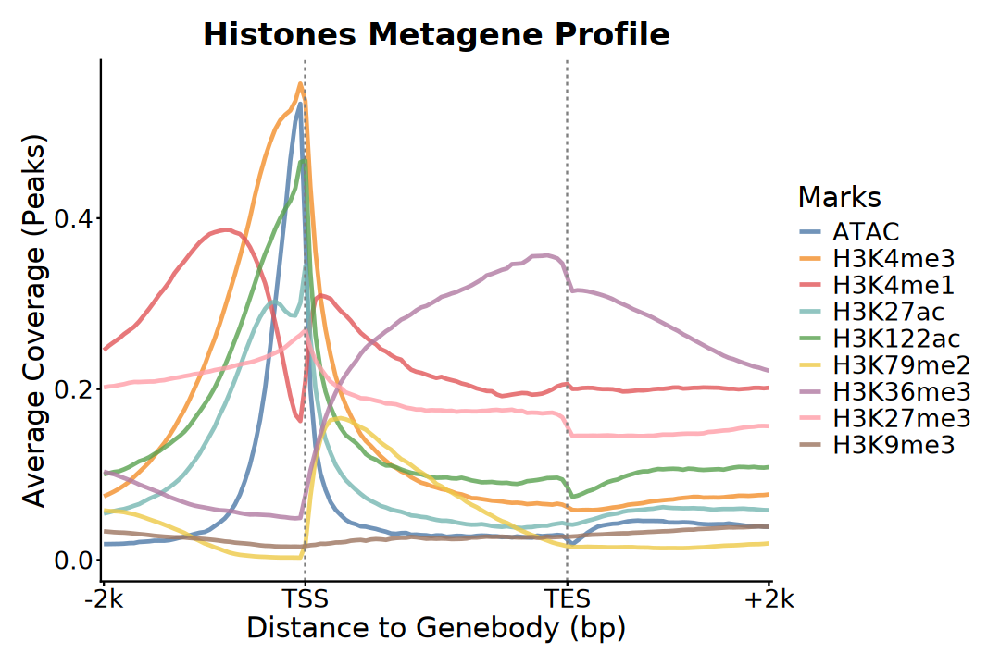

In [ ]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(profiles_df, aes(Position, Coverage)) +
    geom_line(
        aes(color = Marks, group = Marks), 
        alpha = 0.8, linewidth = 1) +
    geom_vline(
        xintercept = c("t1", "t53"), 
        linetype = "dashed", color = "gray50") +
    scale_x_discrete(
        breaks = c("u1", "t1", "t53", "d40"), 
        labels = c("-2k", "TSS", "TES", "+2k")) +
    # scale_color_brewer(palette = "Set1") + 
    ggthemes::scale_color_tableau(palette = "Tableau 10") +
    labs(
        title = "Histones Metagene Profile", 
        x = "Distance to Genebody (bp)",
        y = "Average Coverage (Peaks)") + 
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        legend.position = "right",
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16), 
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 4). Metagene Profile (Signals)

### a). deepTools

In [58]:
atac_matrix_files <- file.path(atacseq_dir, "08_deeptools") |>
    list.files(pattern = "\\.TSS\\.tsv$", full.names = TRUE) |>
    set_names(~ sub("(.*)\\.TSS\\.tsv$", "\\1", basename(.x)))

chip_matrix_files <- file.path(chipseq_dir, "08_deeptools") |>
    list.files(pattern = "\\.TSS\\.tsv$", full.names = TRUE) |>
    set_names(~ sub("(.*)\\.TSS\\.tsv$", "\\1", basename(.x)))

matrix_files <- c(atac_matrix_files, chip_matrix_files)

matrix_files <- matrix_files[grepl("LIF", names(matrix_files))]
names(matrix_files) <- sub("^[^_]+_LIF_", "", names(matrix_files))

paste(names(matrix_files), basename(matrix_files), sep = ": ") |> cat(sep = "\n")

ATAC: mESC_LIF_ATAC.TSS.tsv
H3K122ac: mESC_LIF_H3K122ac.TSS.tsv
H3K27ac: mESC_LIF_H3K27ac.TSS.tsv
H3K27me3: mESC_LIF_H3K27me3.TSS.tsv
H3K36me3: mESC_LIF_H3K36me3.TSS.tsv
H3K4me1: mESC_LIF_H3K4me1.TSS.tsv
H3K4me3: mESC_LIF_H3K4me3.TSS.tsv
H3K79me2: mESC_LIF_H3K79me2.TSS.tsv
H3K9me3: mESC_LIF_H3K9me3.TSS.tsv
Input: mESC_LIF_Input.TSS.tsv


In [59]:
compute_matrix_mean <- function(file, sample) {
    read.table(file, header = FALSE, sep = "\t", skip = 3) |>
        as.matrix() |> colMeans(na.rm = TRUE)
}

In [60]:
profiles_list <- imap(matrix_files, compute_matrix_mean)

In [61]:
profiles_tss <- do.call(cbind, profiles_list) |>
    as.data.frame() |>
    mutate(Position = seq(-2000, 2000, length.out = 400)) |>
    pivot_longer(-Position, names_to = "Sample", values_to = "Signal") |>
    mutate(Marks = factor(Sample, levels = c("ATAC", marks, "Input")))

head(profiles_tss)

Position,Sample,Signal,Marks
<dbl>,<chr>,<dbl>,<fct>
-2000,ATAC,123.1760,ATAC
-2000,H3K122ac,237.8598,H3K122ac
-2000,H3K27ac,167.9320,H3K27ac
-2000,H3K27me3,217.7052,H3K27me3
-2000,H3K36me3,175.4827,H3K36me3
-2000,H3K4me1,250.0242,H3K4me1


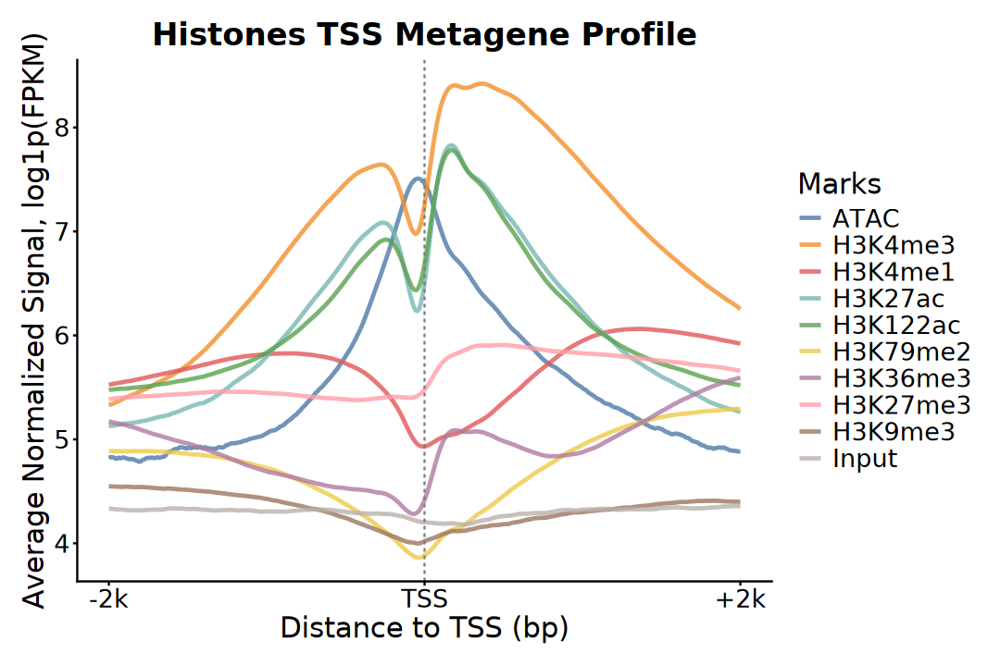

In [62]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(profiles_tss, aes(Position, log1p(Signal))) +
    geom_line(
        aes(color = Marks), alpha = 0.8, linewidth = 1) +
    geom_vline(
        xintercept = 0, linetype = "dashed", color = "gray50") +
    scale_x_continuous(
        breaks = c(-2000, 0, 2000), labels = c("-2k", "TSS", "+2k")) + 
    ggthemes::scale_color_tableau(palette = "Tableau 10") + 
    labs(
        title = "Histones TSS Metagene Profile", 
        x = "Distance to TSS (bp)",
        y = "Average Normalized Signal, log1p(FPKM)") + 
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        panel.spacing = unit(1, "lines"), 
        strip.placement = "outside",
        strip.background = element_blank(),
        strip.text = element_text(size = 18),
        legend.position = "right",
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16), 
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [63]:
atac_matrix_files <- file.path(atacseq_dir, "08_deeptools") |>
    list.files(pattern = "\\.Genebody\\.tsv$", full.names = TRUE) |>
    set_names(~ sub("(.*)\\.Genebody\\.tsv$", "\\1", basename(.x)))

chip_matrix_files <- file.path(chipseq_dir, "08_deeptools") |>
    list.files(pattern = "\\.Genebody\\.tsv$", full.names = TRUE) |>
    set_names(~ sub("(.*)\\.Genebody\\.tsv$", "\\1", basename(.x)))

matrix_files <- c(atac_matrix_files, chip_matrix_files)
matrix_files <- matrix_files[grepl("LIF", names(matrix_files))]
names(matrix_files) <- sub("^[^_]+_LIF_", "", names(matrix_files))

In [64]:
profiles_list <- imap(matrix_files, compute_matrix_mean)

In [65]:
profiles_genebody <- do.call(cbind, profiles_list) |>
    as.data.frame() |>
    mutate(Position = seq(-2000, 5000, length.out = 700)) |>
    pivot_longer(-Position, names_to = "Sample", values_to = "Signal") |>
    mutate(Marks = factor(Sample, levels = c("ATAC", marks, "Input")))

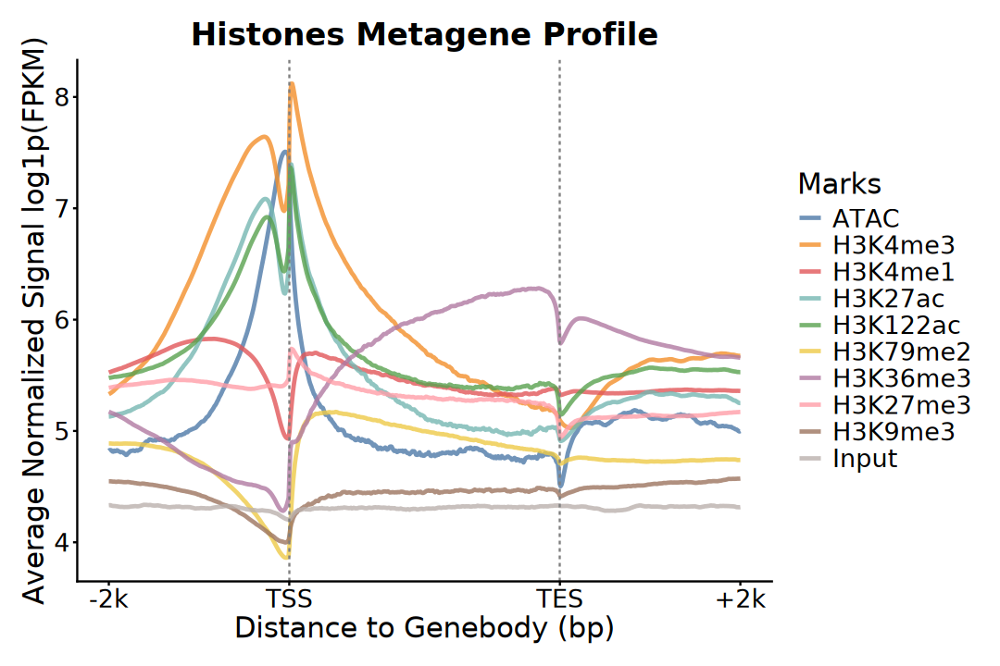

In [66]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(profiles_genebody, aes(Position, log1p(Signal))) +
    geom_line(
        aes(color = Marks), alpha = 0.8, linewidth = 1) +
    geom_vline(
        xintercept = c(0, 3000), linetype = "dashed", color = "gray50") +
    scale_x_continuous(
        breaks = c(-2000, 0, 3000, 5000), 
        labels = c("-2k", "TSS", "TES", "+2k")) + 
    ggthemes::scale_color_tableau(palette = "Tableau 10") + 
    labs(
        title = "Histones Metagene Profile", 
        x = "Distance to Genebody (bp)",
        y = "Average Normalized Signal log1p(FPKM)") + 
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        panel.spacing = unit(1, "lines"), 
        strip.placement = "outside",
        strip.background = element_blank(),
        strip.text = element_text(size = 18),
        legend.position = "right",
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16), 
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

### b). EnrichedHeatmap

In [67]:
# ~ 20 minutes
signals_gene_mat_list <- lapply(
    signals_list, normalizeToMatrix, GENES, 
    value_column = "score", mean_mode = "w0", 
    extend = 2000, w = 50, smooth = TRUE, 
    background = 0, target_ratio = 0.4)

In [68]:
base_colors <- ggthemes::tableau_color_pal("Tableau 10")(
    length(signals_gene_mat_list)) |> 
    setNames(names(signals_gene_mat_list))

col_funs <- lapply(names(signals_gene_mat_list), function(mark) {
    max_val <- abs(signals_gene_mat_list[[mark]]) |>
        quantile(0.95, na.rm = TRUE)
    circlize::colorRamp2(
        c(0, max_val/2, max_val), 
        c("#ffffff", base_colors[mark], "#03045e"))
})

names(col_funs) <- names(signals_gene_mat_list)

In [69]:
lgd_list <- lapply(names(col_funs), function(mark) {
    Legend(
        col_fun = col_funs[[mark]], title = mark, 
        title_gp = gpar(fontsize = 12, fontface = "bold"),
        labels_gp = gpar(fontsize = 10), grid_width = unit(0.4, "cm"))
})

lgd_col1 <- packLegend(list = lgd_list[1:5], direction = "vertical")
lgd_col2 <- packLegend(list = lgd_list[6:10], direction = "vertical")
packed_lgds <- packLegend(
    lgd_col1, lgd_col2, direction = "horizontal", 
    gap = unit(0.8, "cm"))

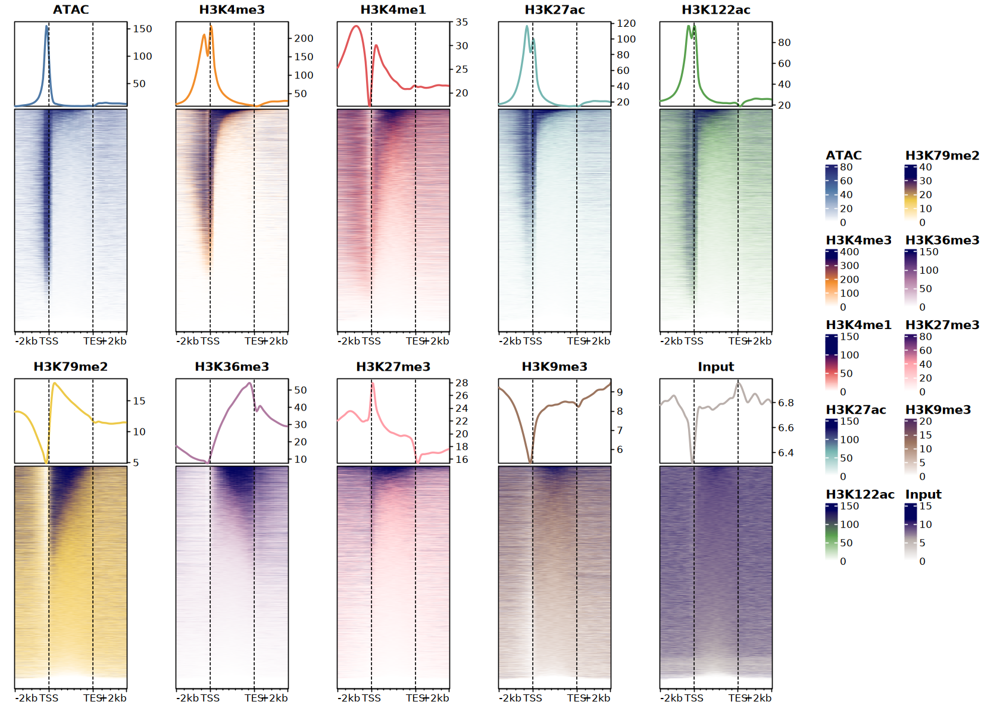

In [ ]:
# ==============================================================================
# ⚠️ WARNING / IMPORTANT NOTE:
# With the current settings, the row order (gene/peak order) across different 
# heatmaps is INCONSISTENT. Each heatmap calculates its own hierarchical 
# clustering independently based on its input matrix. If you want to visually 
# compare rows across different groups, you must enforce a unified row order 
# by setting 'cluster_rows = FALSE' and providing a fixed 'row_order'.
# ==============================================================================

options(repr.plot.width = 14, repr.plot.height = 10)

# Create a new blank canvas
grid.newpage()
# Initialize a grid layout with 2 rows and 5 columns
pushViewport(viewport(layout = grid.layout(
    2, 6, widths = c(1, 1, 1, 1, 1, 1.2))))

for (i in seq_along(signals_gene_mat_list)) {
    mark_name <- names(signals_gene_mat_list)[i]

    # Enter the designated grid slot (viewport)
    row_idx <- if (i <= 5) 1 else 2
    col_idx <- if (i <= 5) i else i - 5
    pushViewport(viewport(layout.pos.row = row_idx, layout.pos.col = col_idx))
    
    # Construct the individual EnrichedHeatmap object
    ht <- EnrichedHeatmap(
        signals_gene_mat_list[[i]], 
        name = mark_name, 
        column_title = mark_name, 
        column_title_gp = gpar(fontsize = 12, fontface = "bold"), 
        col = col_funs[[mark_name]], 
        top_annotation = HeatmapAnnotation(
            lines = anno_enriched(
                gp = gpar(lwd = 2, col = base_colors[mark_name]), 
                axis_param = list(gp = gpar(fontsize = 10))),
            height = unit(3, "cm"), show_legend = FALSE), 
        axis_name = c("-2kb", "TSS", "TES", "+2kb"),
        axis_name_gp = gpar(fontsize = 10),
        show_heatmap_legend = FALSE, 
        show_row_names = FALSE,
        width = unit(4, "cm"),
        use_raster = TRUE)

    # Render the heatmap inside the current viewport
    draw(ht, newpage = FALSE)
    # Exit the current grid slot viewport
    popViewport()
}

pushViewport(viewport(layout.pos.row = 1:2, layout.pos.col = 6))
draw(
    packed_lgds, x = unit(0.1, "npc"), y = unit(0.5, "npc"), 
    just = c("left", "center"))
popViewport()

# Exit the main grid layout viewport
popViewport()

In [71]:
position_levels <- c(
    sprintf("u%d", 1:40), 
    sprintf("t%d", 1:53), 
    sprintf("d%d", 1:40))

profiles_df <- purrr::imap_dfr(
    signals_gene_mat_list, ~ tibble::tibble(
        Position = factor(colnames(.x), levels = position_levels),
        Sample = .y,
        Signal = colMeans(.x, na.rm = TRUE))) |>
    mutate(Marks = factor(Sample, levels = c("ATAC", marks, "Input")))

head(profiles_df)

Position,Sample,Signal,Marks
<fct>,<chr>,<dbl>,<fct>
u1,ATAC,8.840934,ATAC
u2,ATAC,8.566514,ATAC
u3,ATAC,8.721161,ATAC
u4,ATAC,8.867464,ATAC
u5,ATAC,9.005036,ATAC
u6,ATAC,9.182730,ATAC


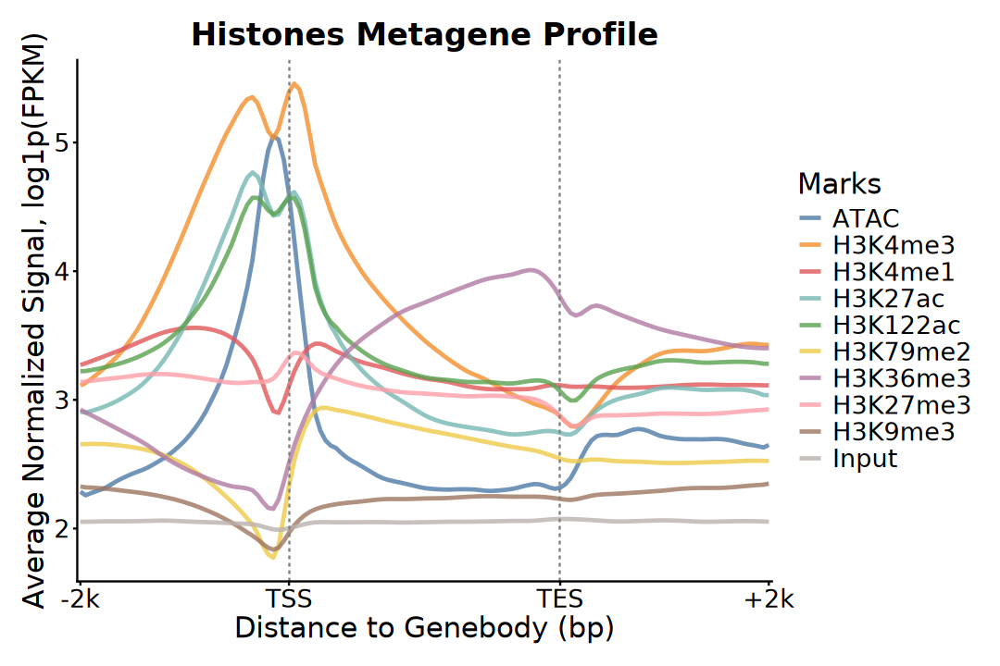

In [ ]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(profiles_df, aes(Position, log1p(Signal))) +
    geom_line(
        aes(color = Marks, group = Marks), 
        alpha = 0.8, linewidth = 1) +
    geom_vline(
        xintercept = c("t1", "t53"), 
        linetype = "dashed", color = "gray50") +
    scale_x_discrete(
        breaks = c("u1", "t1", "t53", "d40"), 
        labels = c("-2k", "TSS", "TES", "+2k")) + 
    # scale_color_brewer(palette = "Set1") + 
    ggthemes::scale_color_tableau(palette = "Tableau 10") +
    labs(
        title = "Histones Metagene Profile", 
        x = "Distance to Genebody (bp)",
        y = "Average Normalized Signal, log1p(FPKM)") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        legend.position = "right",
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16), 
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 5). Genomics Circular

### a). circlize

In [73]:
suppressPackageStartupMessages(library(circlize))

In [74]:
# 1. Read and process chromosome sizes
# library(BSgenome.Mmusculus.UCSC.mm10)
# chrom_sizes <- seqlengths(BSgenome.Mmusculus.UCSC.mm10)
chrom_sizes <- read.table(
    "~/reference/Mus_musculus/mm10/ucsc/mm10.chrom.sizes", 
    header = FALSE, col.names = c("chr", "size")) |> 
    filter(chr %in% standard_chromosome) |>
    pull(var = size, name = chr)

# 2. Generate genomic bins (1Mb window)
bins <- tileGenome(
    seqlengths = chrom_sizes, tilewidth = 1e6, 
    cut.last.tile.in.chrom = TRUE)

# 3. Calculate gene density per bin
bins$gene_density <- countOverlaps(bins, GENES)

In [75]:
# 4. Calculate mean signal scores for target modifications
target_mods <- c("ATAC", "H3K4me3", "H3K27me3")

for (mod_name in target_mods) {
    gr <- signals_list[[mod_name]]
    hits <- findOverlaps(bins, gr)
    
    # Extract scores based on subject hits
    scores <- mcols(gr)$score[subjectHits(hits)]    
    avg_score <- tapply(scores, queryHits(hits), mean)
    
    # Initialize zero vector and assign calculated means based on indices
    bins_vector <- rep(0, length(bins))
    bins_vector[as.integer(names(avg_score))] <- as.numeric(avg_score)
    # Assign back to metadata columns of the bins GRanges object
    mcols(bins)[[mod_name]] <- bins_vector
}

# 5. Prepare data frames for plotting
df_all <- as.data.frame(bins)
df_signal <- df_all[, c("seqnames", "start", "end", target_mods)]


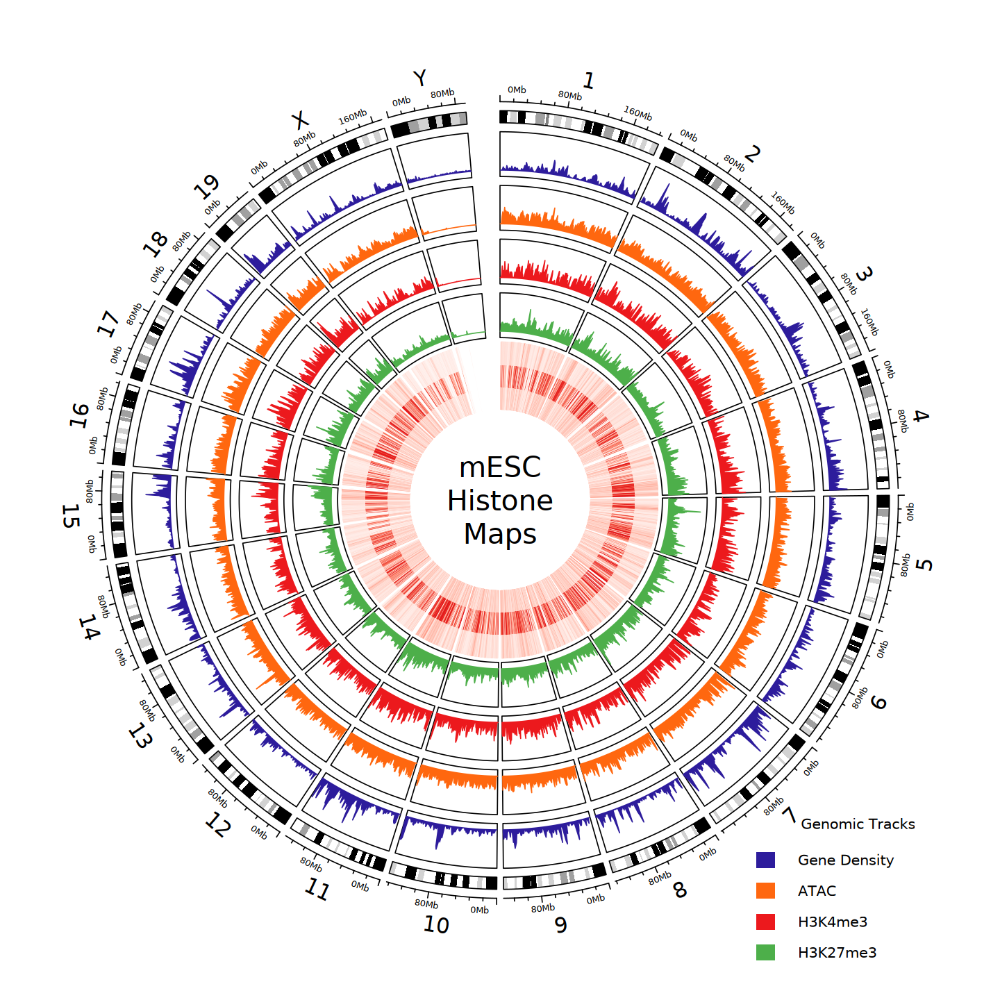

In [76]:
# 6. Setup Circos plot parameters
options(repr.plot.width = 12, repr.plot.height = 12)

circos.par(
    start.degree = 90, track.margin = c(0.01, 0.01),
    gap.after = c(rep(1, length(standard_chromosome)-1), 5))

circos.initializeWithIdeogram(
    species = "mm10", track.height = 0.1, 
    chromosome.index = standard_chromosome, 
    labels.cex = 1.5, axis.labels.cex = 0.6)

# Add center annotation text
text(0, 0, "mESC\nHistone\nMaps", cex = 2)

# 7. Define helper function for plotting signal tracks
plot_peak_track <- function(data_col, color, track_height = 0.1, use_log = FALSE) {
    df_track <- df_all[, c("seqnames", "start", "end", data_col)]
    
    # Apply log2 transformation if requested
    if (use_log) {
        df_track[[data_col]] <- log2(df_track[[data_col]] + 1)
    }    
    
    circos.genomicTrack(
        df_track, track.height = track_height, 
        panel.fun = function(region, value, ...) {
            circos.genomicLines(
                region, value, 
                area = TRUE, baseline = 0, 
                col = color, border = color
            )
        }
    )
}

# 8. Plot individual signal tracks
plot_peak_track("gene_density", color = "#2d1c9c")
plot_peak_track("ATAC", color = "#ff670f")
plot_peak_track("H3K4me3", color = "#ec191d")
plot_peak_track("H3K27me3", color = "#4daf4a")

# 9. Plot inner heatmap
max_val <- quantile(as.matrix(df_signal[, -c(1:3)]), 0.95, na.rm = TRUE)
col_fun <- colorRamp2(c(0, max_val), c("white", "#e41a1c"))

circos.genomicHeatmap(
    df_signal, 
    col = col_fun, 
    side = "inside", 
    border = NA, 
    connection_height = NULL
)

# 10. Add legend to the plot
legend(
    "bottomright", horiz = FALSE, 
    legend = c("Gene Density", "ATAC", "H3K4me3", "H3K27me3"), 
    fill = c("#2d1c9c", "#ff670f", "#ec191d", "#4daf4a"),
    border = NA, bty = "n", cex = 1, title = "Genomic Tracks"
)

# 11. Clear Circos parameters (crucial for rendering subsequent plots cleanly)
circos.clear()

### b). RCircos

> RCircos is an easy-to-use R package for generating 2D circular (Circos) plots, widely used for visualizing genomic data. However, its rigid, hard-coded base graphics architecture substantially limits advanced customization and extensibility. Although custom rendering is still possible by overriding internal functions, doing so can be cumbersome and difficult to maintain.
> - Zhang, H., Meltzer, P. & Davis, S. RCircos: an R package for Circos 2D track plots. BMC Bioinformatics 14, 244 (2013). https://doi.org/10.1186/1471-2105-14-244

In [77]:
suppressPackageStartupMessages(library(RCircos))

In [78]:
# 1. Load CytoBand Ideogram data
data(UCSC.Mouse.GRCm38.CytoBandIdeogram)
CytoBandIdeogram <- UCSC.Mouse.GRCm38.CytoBandIdeogram

# 2. Generate genomic bins (1Mb window)
chrom_sizes <- read.table(
    "~/reference/Mus_musculus/mm10/ucsc/mm10.chrom.sizes", 
    header = FALSE, col.names = c("chr", "size")) |> 
    filter(chr %in% standard_chromosome) |>
    pull(var = size, name = chr)
bins <- tileGenome(
    seqlengths = chrom_sizes, tilewidth = 1e6, 
    cut.last.tile.in.chrom = TRUE)

seqlevels(bins) <- names(seqlengths(signals_list$H3K4me3))

In [79]:
# 3. Prepare target genes data
RCircos_Genes_Dat <- subset(
    GENES, gene_name %in% c(
        "Nanog", "Sox2", "Pou5f1", "Hoxa1", "Hoxb4", 
        "Hoxa5", "Hoxc8", "Hoxd10", "Hoxd13"), 
    select = "gene_name") |> 
    as.data.frame() |>
    dplyr::select(
        Chromosome = seqnames, chromStart = start, 
        chromEnd = end, Gene = gene_name)

head(RCircos_Genes_Dat)

,Chromosome,chromStart,chromEnd,Gene
,<fct>,<int>,<int>,<chr>
1,chr2,74668310,74671599,Hoxd13
2,chr2,74691924,74695105,Hoxd10
3,chr3,34650405,34652461,Sox2
4,chr6,52155590,52158317,Hoxa1
5,chr6,52201754,52204587,Hoxa5
6,chr6,122707489,122714633,Nanog


In [80]:
# 4. Calculate coverage for all target modifications
target_mods <- c("ATAC", "H3K4me3", "H3K27me3")

for (mod_name in target_mods) {
    signals_rle <- coverage(signals_list[[mod_name]], weight = "score")
    bins <- binnedAverage(bins, signals_rle, mod_name)
}

# 5. Extract to RCircos compatible dataframe format
RCircos_Signal_Dat <- bins |>
    as.data.frame() |>
    dplyr::select(
        Chromosome = seqnames, chromStart = start, 
        chromEnd = end, ATAC, H3K4me3, H3K27me3)

head(RCircos_Signal_Dat)

,Chromosome,chromStart,chromEnd,ATAC,H3K4me3,H3K27me3
,<fct>,<int>,<int>,<dbl>,<dbl>,<dbl>
1,chr1,1,1000000,0.000000,0.000000,0.000000
2,chr1,1000001,2000000,0.000000,0.000000,0.000000
3,chr1,2000001,3000000,0.000000,0.000000,0.000000
4,chr1,3000001,4000000,3.184874,2.313995,9.952152
5,chr1,4000001,5000000,6.621732,9.459414,11.706766
6,chr1,5000001,6000000,3.706204,3.722624,11.610976



RCircos.Core.Components initialized.
Type ?RCircos.Reset.Plot.Parameters to see how to modify the core components.





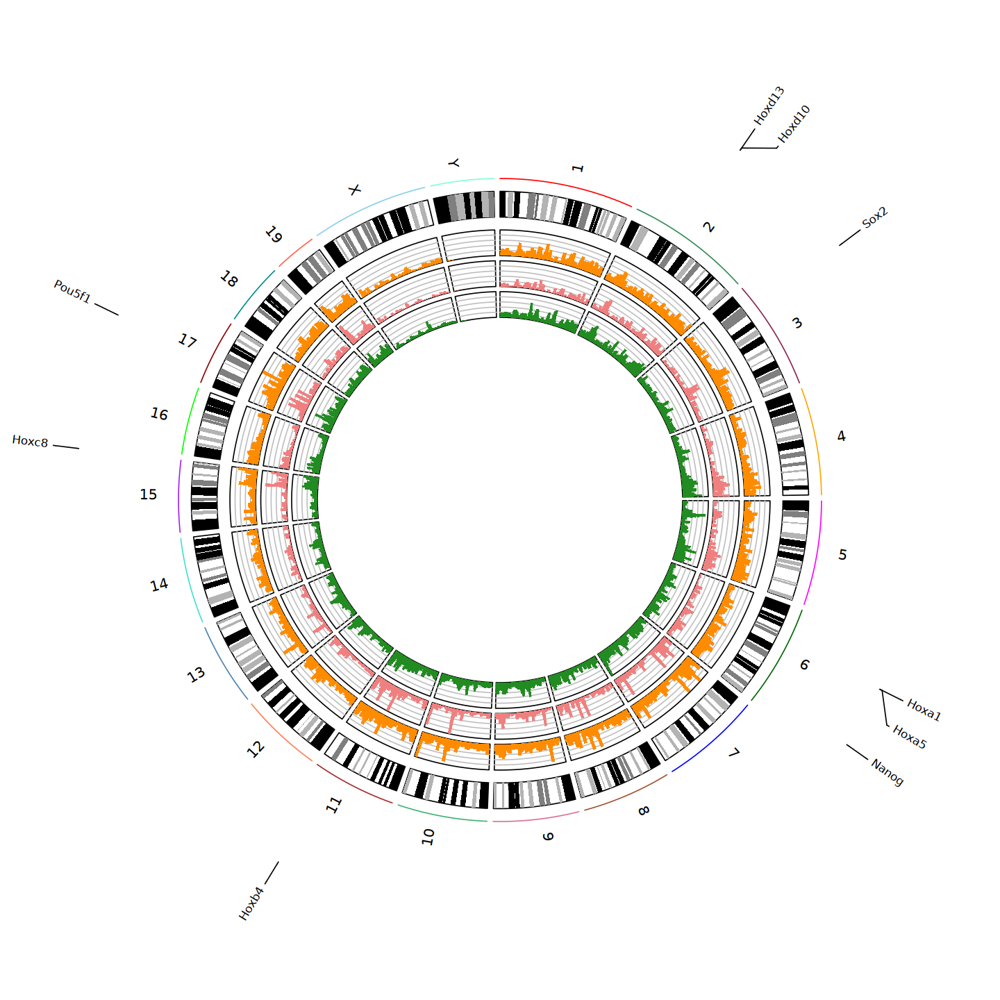

In [81]:
options(repr.plot.width = 12, repr.plot.height = 12)

# 6. Initialize RCircos parameters
RCircos.Set.Core.Components(
    cyto.info = CytoBandIdeogram, chr.exclude = NULL, 
    tracks.inside = 3, tracks.outside = 2)

params <- RCircos.Get.Plot.Parameters()
params$track.height <- 0.1
params$track.background <- "white"
params$text.size <- 0.8
RCircos.Reset.Plot.Parameters(params)

# 7. Setup Plot Area
# RCircos.Set.Plot.Area()
par(mai = c(0, 0, 0, 0)) 
plot.new()
plot.window(c(-1.8, 1.8), c(-1.8, 1.8), asp = 1)

# Plot Chromosome Ideogram
RCircos.Chromosome.Ideogram.Plot()

# Plot Gene Connectors (Track 1) and Names (Track 2)
# RCircos.Vertical.Line.Plot(
#     RCircos_Genes_Dat, track.num = 1, side = "out")
RCircos.Gene.Connector.Plot(
    RCircos_Genes_Dat, track.num = 1, side = "out")
RCircos.Gene.Name.Plot(
    RCircos_Genes_Dat, name.col = 4, track.num = 2, side = "out")

# 8. Plot Histograms Track by Track with Custom Colors

# Track 4: ATAC
params <- RCircos.Get.Plot.Parameters()
params$hist.color <- "darkorange"
RCircos.Reset.Plot.Parameters(params)

RCircos.Histogram.Plot(
    RCircos_Signal_Dat, data.col = 4, track.num = 1, side = "in")

# Track 5: H3K4me3
params <- RCircos.Get.Plot.Parameters()
params$hist.color <- "lightcoral"
RCircos.Reset.Plot.Parameters(params)

RCircos.Histogram.Plot(
    RCircos_Signal_Dat, data.col = 5, track.num = 2, side = "in")

# Track 6: H3K27me3
params <- RCircos.Get.Plot.Parameters()
params$hist.color <- "forestgreen"
RCircos.Reset.Plot.Parameters(params)

RCircos.Histogram.Plot(
    RCircos_Signal_Dat, data.col = 6, track.num = 3, side = "in")

### c). ggbio

> R package for extending the grammar of graphics for genomic data
> - Yin, T., Cook, D. & Lawrence, M. ggbio: an R package for extending the grammar of graphics for genomic data. Genome Biol 13, R77 (2012). https://doi.org/10.1186/gb-2012-13-8-r77

### d). interacCircos

> The interacCircos package is designed for the generation of interactive Circos plot
> - Zhe Cui, Ya Cui, Tianyi Zang, Yadong Wang, interacCircos: an R package based on JavaScript libraries for the generation of interactive circos plots, Bioinformatics, Volume 37, Issue 20, October 2021, Pages 3642–3644, https://doi.org/10.1093/bioinformatics/btab232

## 6). IGV snapshot

In [82]:
suppressPackageStartupMessages(library(Gviz))
suppressPackageStartupMessages(library(AnnotationHub))

In [83]:
# Hoxa
genome = "mm10"
target_region <- "chr6:52150000-52230000"

In [84]:
target_region <- str_match(target_region, "([^:]+):(\\d+)-(\\d+)") |> 
    as.data.frame() |>
    transmute(
        pos = V1, chr = V2, start = as.numeric(V3), 
        end = as.numeric(V4)) |>
    column_to_rownames("pos")
target_region

,chr,start,end
,<chr>,<dbl>,<dbl>
chr6:52150000-52230000,chr6,52150000,52230000


In [85]:
ah <- AnnotationHub()
query(ah, "UCSC cytoBand track for mm10")

AnnotationHub with 1 record
# snapshotDate(): 2025-10-29
# names(): AH53180
# $dataprovider: UCSC
# $species: Mus musculus
# $rdataclass: GRanges
# $rdatadateadded: 2017-01-05
# $title: UCSC cytoBand track for mm10
# $description: Approximate location of bands seen on Giemsa-stained chromos...
# $taxonomyid: 10090
# $genome: mm10
# $sourcetype: UCSC track
# $sourceurl: http://hgdownload.cse.ucsc.edu/goldenpath/mm10/database/cytoBa...
# $sourcesize: NA
# $tags: c("cytoBand", "AHCytoBands") 
# retrieve record with 'object[["AH53180"]]' 

In [86]:
bands <- ah[["AH53180"]] |> 
    as.data.frame() |> 
    dplyr::rename(
        chrom = seqnames, chromStart = start, chromEnd = end)

loading from cache



In [87]:
idTrack <- IdeogramTrack(
    chromosome = target_region$chr, genome = genome, 
    name = str_to_title(target_region$chr), bands = bands,
    fontcolor = "black", fontsize = 20)
scale_bar <- GenomeAxisTrack(
    scale = 0.1, col = "black", fontcolor = "black", 
    labelPos = "above", showTitle = FALSE, fontsize = 16,
    distFromAxis = 1, lwd = 1)
coordinate <- GenomeAxisTrack(
    labelPos = "above", col = "black", fontcolor = "black", 
    exponent = 0, showTitle = FALSE, fontsize = 14, lwd = 2)

plot_list <- list(idTrack, scale_bar, coordinate)

In [88]:
colors_palette <- colorRampPalette(
    brewer.pal(8, "Set2"))(length(signals_list))
names(colors_palette) <- names(signals_list)

In [89]:
signal_tracks <- purrr::imap(
    signals_list, ~ Gviz::DataTrack(
        range = .x, name = .y, type = "histogram",
        chromosome = target_region$chr, genome = genome,
        showTitle = TRUE, fontsize = 12, cex.title = 1, cex.axis = 0.8,
        col.title = "black", fontcolor.title = "black",
        col.histogram = colors_palette[.y],
        fill.histogram = colors_palette[.y]
    )
)

In [90]:
grtrack <- GeneRegionTrack(
    txdb, genome = genome, chromosome = target_region$chr, 
    start = target_region$start, end = target_region$end,
    transcriptAnnotation = "symbol", showId = TRUE, geneSymbol = TRUE, 
    collapseTranscripts = "longest", fontsize = 20, 
    cex.title = 1, fontsize.group = 16, rotation.title = 0,
    name = "Gene", col = "grey", fill = "orange", 
    fontcolor.group = "black", stacking = "squish")

gene_info <- filter(gtf, type == "gene")

ranges(grtrack)$symbol <- gene_info$gene_name[
    match(ranges(grtrack)$gene, gene_info$gene_id)]

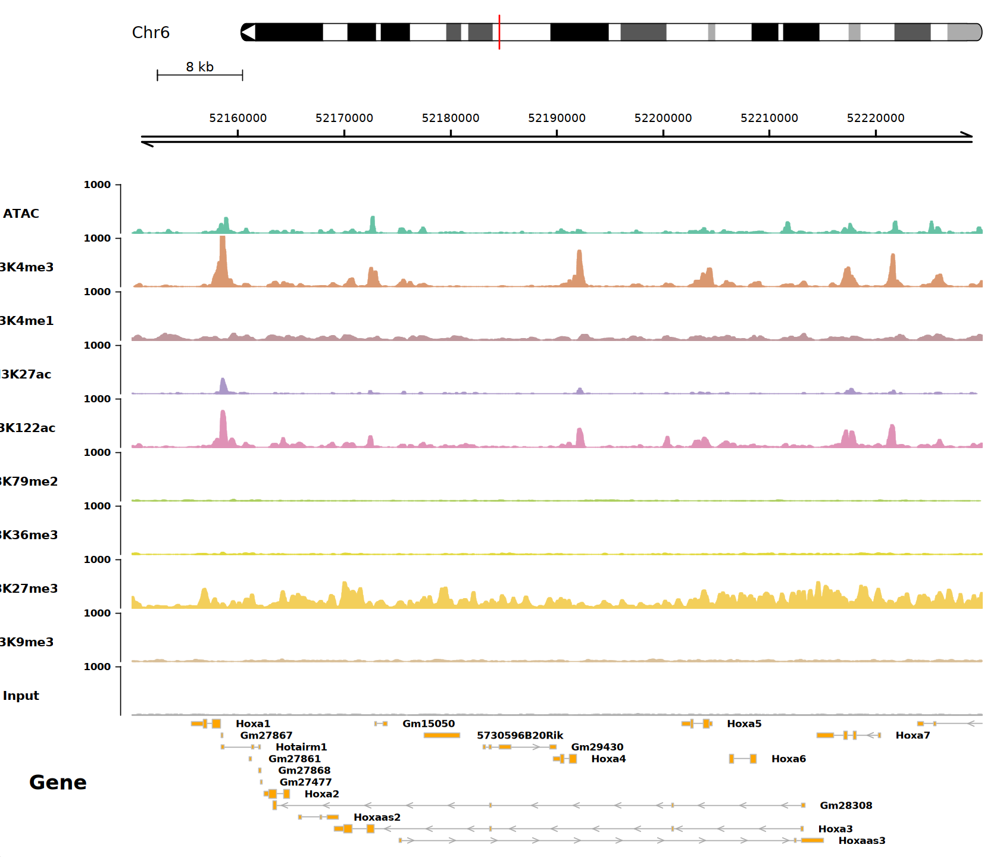

In [ ]:
options(repr.plot.width = 14, repr.plot.height = 12)

plotTracks(
    trackList = c(plot_list, signal_tracks, grtrack), 
    chromosome = target_region$chr, 
    from = target_region$start, to = target_region$end, 
    background.title = "white", col.title = "black", col.axis = "black", 
    sizes = c(2, 2, 4, rep(2.5, length(signals_list)), 6), 
    reverseStrand = FALSE, rotation.title = 0, title.width = 1, 
    just.group = "right", extend.left = 0, 
    ylim = c(0, 1000), yTicksAt = c(1000))

# 5. Promoter

In [92]:
promoter_regions <- promoters(GENES, upstream = 2000, downstream = 2000)
tss_sites <- resize(promoter_regions, width = 1, fix = "center")

In [93]:
# ~ 10 minutes
signals_tss_mat_list <- lapply(
    signals_list, normalizeToMatrix, tss_sites, 
    value_column = "score", mean_mode = "w0", 
    extend = 2000, w = 50, smooth = TRUE, 
    background = 0)

In [94]:
h3k4me3_mean  <- rowMeans(signals_tss_mat_list[["H3K4me3"]])
h3k27me3_mean <- rowMeans(signals_tss_mat_list[["H3K27me3"]])

## 1). K-means clustering

In [95]:
num_clusters <- 4

set.seed(123)
km_fit <- do.call(cbind, signals_tss_mat_list[c("H3K4me3", "H3K27me3")]) |>
    kmeans(centers = num_clusters, iter.max = 50)

unified_clusters <- paste0("C", km_fit$cluster)
unified_row_order <- order(h3k4me3_mean, decreasing = TRUE)

print(table(unified_clusters))

unified_clusters
   C1    C2    C3    C4 
 5418  1883 13030  1505 


In [96]:
base_colors <- ggthemes::tableau_color_pal("Tableau 10")(
    length(signals_tss_mat_list)) |> 
    setNames(names(signals_tss_mat_list))

col_funs <- lapply(names(signals_tss_mat_list), function(mark) {
    max_val <- abs(signals_tss_mat_list[[mark]]) |>
        quantile(0.95, na.rm = TRUE)
    circlize::colorRamp2(
        c(0, max_val/2, max_val), 
        c("#ffffff", base_colors[mark], "#03045e"))
})

names(col_funs) <- names(signals_tss_mat_list)

cluster_colors <- c(
    "C1" = "#e15759", "C2" = "#f28e2b",
    "C3" = "#4e79a7", "C4" = "#76b7b2")

In [97]:
lgd_list <- lapply(names(col_funs), function(mark) {
    Legend(
        col_fun = col_funs[[mark]], title = mark, 
        title_gp = gpar(fontsize = 12, fontface = "bold"),
        labels_gp = gpar(fontsize = 10), grid_width = unit(0.4, "cm"))
})

line_lgd <- Legend(
    labels = paste0("Cluster ", 1:num_clusters),
    title = "Promoter Class",
    legend_gp = gpar(col = cluster_colors[1:num_clusters], lwd = 2),
    type = "lines",
    title_gp = gpar(fontsize = 12, fontface = "bold"),
    labels_gp = gpar(fontsize = 10)
)

lgd_col1 <- packLegend(list = lgd_list[1:5], direction = "vertical")
lgd_col2 <- packLegend(list = lgd_list[6:10], direction = "vertical")
packed_lgds <- packLegend(
    lgd_col1, lgd_col2, direction = "horizontal", gap = unit(0.8, "cm")) |>
    packLegend(line_lgd, direction = "vertical", gap = unit(0.8, "cm"))

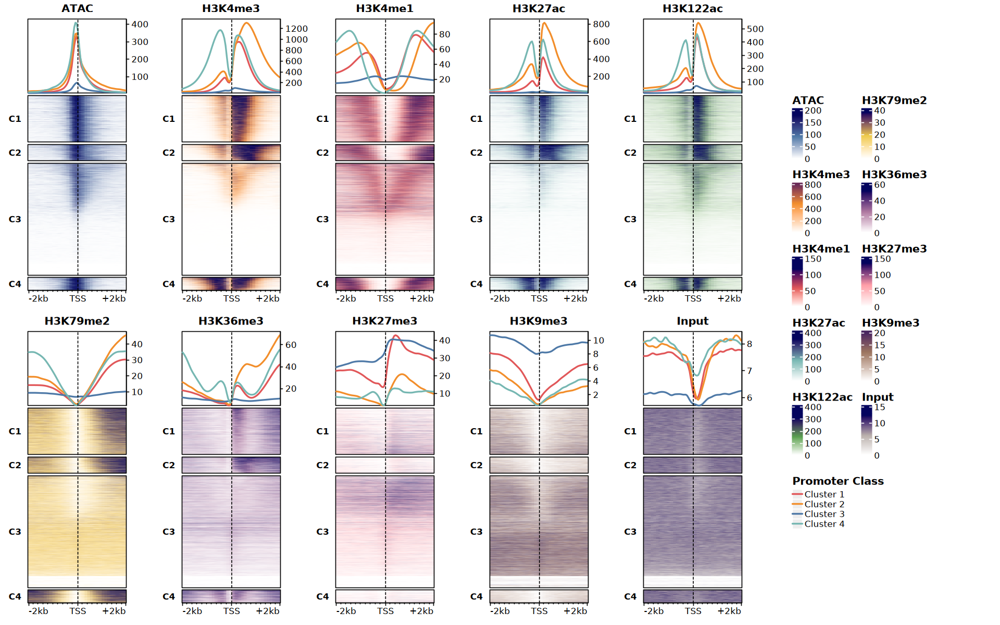

In [98]:
options(repr.plot.width = 16, repr.plot.height = 10)

# Create a new blank canvas
grid.newpage()
# Initialize a grid layout with 2 rows and 5 columns
pushViewport(viewport(layout = grid.layout(
    2, 6, widths = c(1, 1, 1, 1, 1, 1.5))))

for (i in seq_along(signals_tss_mat_list)) {
    mark_name <- names(signals_tss_mat_list)[i]

    # Enter the designated grid slot (viewport)
    row_idx <- if (i <= 5) 1 else 2
    col_idx <- if (i <= 5) i else i - 5
    pushViewport(viewport(layout.pos.row = row_idx, layout.pos.col = col_idx))
    
    # Construct the individual EnrichedHeatmap object
    ht <- EnrichedHeatmap(
        signals_tss_mat_list[[i]], 
        name = mark_name, 
        column_title = mark_name, 
        column_title_gp = gpar(fontsize = 12, fontface = "bold"),
        col = col_funs[[mark_name]], 
        top_annotation = HeatmapAnnotation(
            lines = anno_enriched(
                gp = gpar(lwd = 2, col = cluster_colors), 
                axis_param = list(gp = gpar(fontsize = 10))),
            height = unit(3, "cm"), show_legend = FALSE), 
        cluster_rows = FALSE,            
        row_order = unified_row_order,   
        row_split = unified_clusters,
        row_title_rot = 0,
        row_title_gp = gpar(fontsize = 10, fontface = "bold"),
        axis_name = c("-2kb", "TSS", "+2kb"),
        axis_name_gp = gpar(fontsize = 10),
        show_heatmap_legend = FALSE, 
        show_row_names = FALSE,
        width = unit(4, "cm"),
        use_raster = TRUE)

    # Render the heatmap inside the current viewport
    draw(ht, newpage = FALSE)
    # Exit the current grid slot viewport
    popViewport()
}

pushViewport(viewport(layout.pos.row = 1:2, layout.pos.col = 6))
draw(
    packed_lgds, x = unit(0.1, "npc"), y = unit(0.5, "npc"), 
    just = c("left", "center"))
popViewport()

# Exit the main grid layout viewport
popViewport()

## 2). Heuristic threshold classification

In [99]:
cutoff_k4  <- quantile(h3k4me3_mean, 0.75)
cutoff_k27 <- quantile(h3k27me3_mean, 0.75)

unified_clusters <- case_when(
    h3k4me3_mean >= cutoff_k4 & h3k27me3_mean >= cutoff_k27 ~ "Bivalent",
    h3k4me3_mean >= cutoff_k4 & h3k27me3_mean <  cutoff_k27 ~ "Active",
    h3k4me3_mean <  cutoff_k4 & h3k27me3_mean >= cutoff_k27 ~ "Repressed",
    TRUE                                                    ~ "Inactive"
)

unified_row_order <- order(
    factor(unified_clusters, levels = c(
        "Active", "Bivalent", "Repressed", "Inactive")), 
    h3k4me3_mean, 
    decreasing = TRUE)

print(table(unified_clusters))

unified_clusters
   Active  Bivalent  Inactive Repressed 
     4990       469     11387      4990 


In [100]:
h3k4me3_peaks  <- peaks_list[["H3K4me3"]]
h3k27me3_peaks <- peaks_list[["H3K27me3"]]

has_k4me3  <- tss_sites %over% h3k4me3_peaks
has_k27me3 <- tss_sites %over% h3k27me3_peaks

unified_clusters <- case_when(
    has_k4me3 & has_k27me3  ~ "Bivalent",
    has_k4me3 & !has_k27me3 ~ "Active",
    !has_k4me3 & has_k27me3 ~ "Repressed",
    TRUE                    ~ "Inactive"
)

unified_row_order <- order(
    factor(unified_clusters, levels = c(
        "Active", "Bivalent", "Repressed", "Inactive")), 
    h3k4me3_mean, 
    decreasing = TRUE
)

print(table(unified_clusters))

unified_clusters
   Active  Bivalent  Inactive Repressed 
     8908      3497      7130      2301 


In [101]:
base_colors <- ggthemes::tableau_color_pal("Tableau 10")(
    length(signals_tss_mat_list)) |> 
    setNames(names(signals_tss_mat_list))

col_funs <- lapply(names(signals_tss_mat_list), function(mark) {
    max_val <- abs(signals_tss_mat_list[[mark]]) |>
        quantile(0.95, na.rm = TRUE)
    circlize::colorRamp2(
        c(0, max_val/2, max_val), 
        c("#ffffff", base_colors[mark], "#03045e"))
})

names(col_funs) <- names(signals_tss_mat_list)

cluster_colors <- c(
    "Active"      = "#e15759",
    "Bivalent"    = "#f28e2b",
    "Repressed"   = "#4e79a7",
    "Inactive"    = "#76b7b2")

In [102]:
lgd_list <- lapply(names(col_funs), function(mark) {
    Legend(
        col_fun = col_funs[[mark]], title = mark, 
        title_gp = gpar(fontsize = 12, fontface = "bold"),
        labels_gp = gpar(fontsize = 10), grid_width = unit(0.4, "cm"))
})

line_lgd <- Legend(
    labels = c("Active", "Bivalent", "Repressed", "Inactive"),
    title = "Promoter Class",
    legend_gp = gpar(col = cluster_colors[1:num_clusters], lwd = 2),
    type = "lines",
    title_gp = gpar(fontsize = 12, fontface = "bold"),
    labels_gp = gpar(fontsize = 10)
)

lgd_col1 <- packLegend(list = lgd_list[1:5], direction = "vertical")
lgd_col2 <- packLegend(list = lgd_list[6:10], direction = "vertical")
packed_lgds <- packLegend(
    lgd_col1, lgd_col2, direction = "horizontal", gap = unit(0.8, "cm")) |>
    packLegend(line_lgd, direction = "vertical", gap = unit(0.8, "cm"))

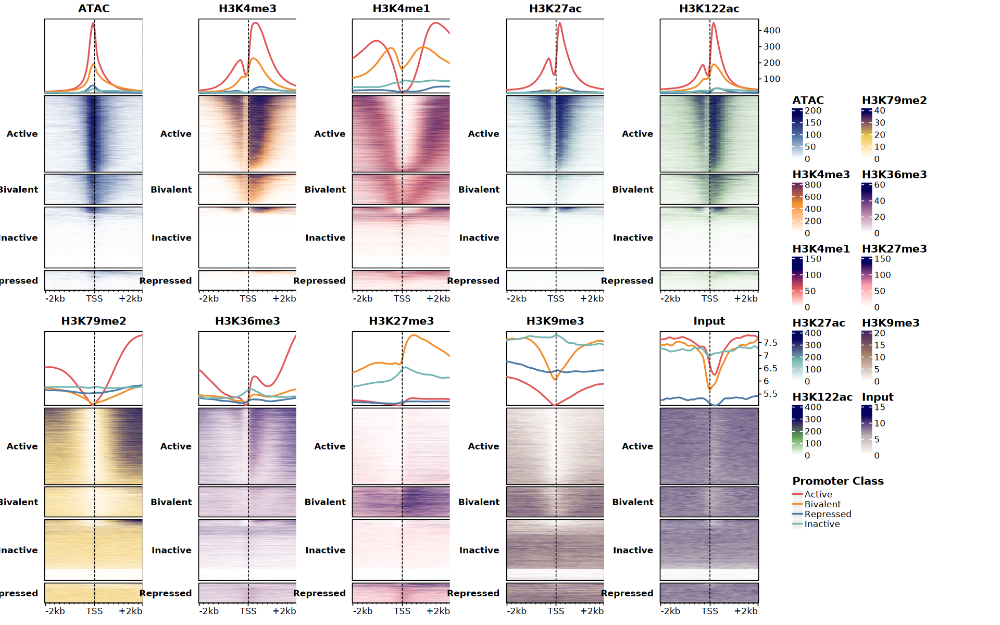

In [103]:
options(repr.plot.width = 16, repr.plot.height = 10)

# Create a new blank canvas
grid.newpage()
# Initialize a grid layout with 2 rows and 5 columns
pushViewport(viewport(layout = grid.layout(
    2, 6, widths = c(1, 1, 1, 1, 1, 1.5))))

for (i in seq_along(signals_tss_mat_list)) {
    mark_name <- names(signals_tss_mat_list)[i]

    # Enter the designated grid slot (viewport)
    row_idx <- if (i <= 5) 1 else 2
    col_idx <- if (i <= 5) i else i - 5
    pushViewport(viewport(layout.pos.row = row_idx, layout.pos.col = col_idx))
    
    # Construct the individual EnrichedHeatmap object
    ht <- EnrichedHeatmap(
        signals_tss_mat_list[[i]], 
        name = mark_name, 
        column_title = mark_name, 
        column_title_gp = gpar(fontsize = 12, fontface = "bold"),
        col = col_funs[[mark_name]], 
        top_annotation = HeatmapAnnotation(
            lines = anno_enriched(
                gp = gpar(lwd = 2, col = cluster_colors), 
                axis_param = list(gp = gpar(fontsize = 10))),
            height = unit(3, "cm"), show_legend = FALSE), 
        cluster_rows = FALSE,            
        row_order = unified_row_order,   
        row_split = unified_clusters,
        row_title_rot = 0,
        row_title_gp = gpar(fontsize = 10, fontface = "bold"),
        axis_name = c("-2kb", "TSS", "+2kb"),
        axis_name_gp = gpar(fontsize = 10),
        show_heatmap_legend = FALSE, 
        show_row_names = FALSE,
        width = unit(4, "cm"),
        use_raster = TRUE)

    # Render the heatmap inside the current viewport
    draw(ht, newpage = FALSE)
    # Exit the current grid slot viewport
    popViewport()
}

pushViewport(viewport(layout.pos.row = 1:2, layout.pos.col = 6))
draw(
    packed_lgds, x = unit(0.1, "npc"), y = unit(0.5, "npc"), 
    just = c("left", "center"))
popViewport()

# Exit the main grid layout viewport
popViewport()

# 6. Enhancer

In [104]:
tss_regions <- promoters(GENES, upstream = 3000, downstream = 3000)

distal_enhancers <- subsetByOverlaps(
    peaks_list[["H3K4me1"]], tss_regions, invert = TRUE)

enhancer_centers <- resize(distal_enhancers, width = 1, fix = "center")

In [105]:
# ~ 40 minutes
signals_enh_mat_list <- lapply(
    signals_list, normalizeToMatrix, enhancer_centers, 
    value_column = "score", mean_mode = "w0", 
    extend = 2000, w = 50, smooth = TRUE, 
    background = 0)

In [106]:
has_k27ac  <- enhancer_centers %over% peaks_list[["H3K27ac"]]
has_k27me3 <- enhancer_centers %over% peaks_list[["H3K27me3"]]
has_atac   <- enhancer_centers %over% peaks_list[["ATAC"]]

enhancer_clusters <- case_when(
    has_k27ac & !has_k27me3  ~ "Active",
    !has_k27ac & has_k27me3  ~ "Poised",
    !has_k27ac & !has_k27me3 ~ "Primed",
    TRUE                     ~ "Other"
)

print(table(enhancer_clusters))

h3k4me1_mean <- rowMeans(signals_enh_mat_list[["H3K4me1"]])

unified_row_order_enh <- order(
    factor(enhancer_clusters, levels = c(
        "Active", "Poised", "Primed", "Other")), 
    h3k4me1_mean, 
    decreasing = TRUE
)

enhancer_clusters
Active  Other Poised Primed 
  8490    311  14957  80974 


In [107]:
base_colors <- ggthemes::tableau_color_pal("Tableau 10")(
    length(signals_enh_mat_list)) |> 
    setNames(names(signals_enh_mat_list))

col_funs <- lapply(names(signals_enh_mat_list), function(mark) {
    max_val <- abs(signals_enh_mat_list[[mark]]) |>
        quantile(0.95, na.rm = TRUE)
    circlize::colorRamp2(
        c(0, max_val/2, max_val), 
        c("#ffffff", base_colors[mark], "#03045e"))
})

names(col_funs) <- names(signals_enh_mat_list)

enh_cluster_colors <- c(
    "Active" = "#e15759",
    "Poised" = "#f28e2b",
    "Primed" = "#4e79a7",
    "Other"  = "#76b7b2"
)

In [108]:
lgd_list <- lapply(names(col_funs), function(mark) {
    Legend(
        col_fun = col_funs[[mark]], title = mark, 
        title_gp = gpar(fontsize = 12, fontface = "bold"),
        labels_gp = gpar(fontsize = 10), grid_width = unit(0.4, "cm"))
})

line_lgd <- Legend(
    labels = c("Active", "Poised", "Primed", "Other"),
    title = "Enhancer Class",
    legend_gp = gpar(col = enh_cluster_colors[1:4], lwd = 2),
    type = "lines",
    title_gp = gpar(fontsize = 12, fontface = "bold"),
    labels_gp = gpar(fontsize = 10)
)

lgd_col1 <- packLegend(list = lgd_list[1:5], direction = "vertical")
lgd_col2 <- packLegend(list = lgd_list[6:10], direction = "vertical")
packed_lgds <- packLegend(
    lgd_col1, lgd_col2, direction = "horizontal", gap = unit(0.8, "cm")) |>
    packLegend(line_lgd, direction = "vertical", gap = unit(0.8, "cm"))

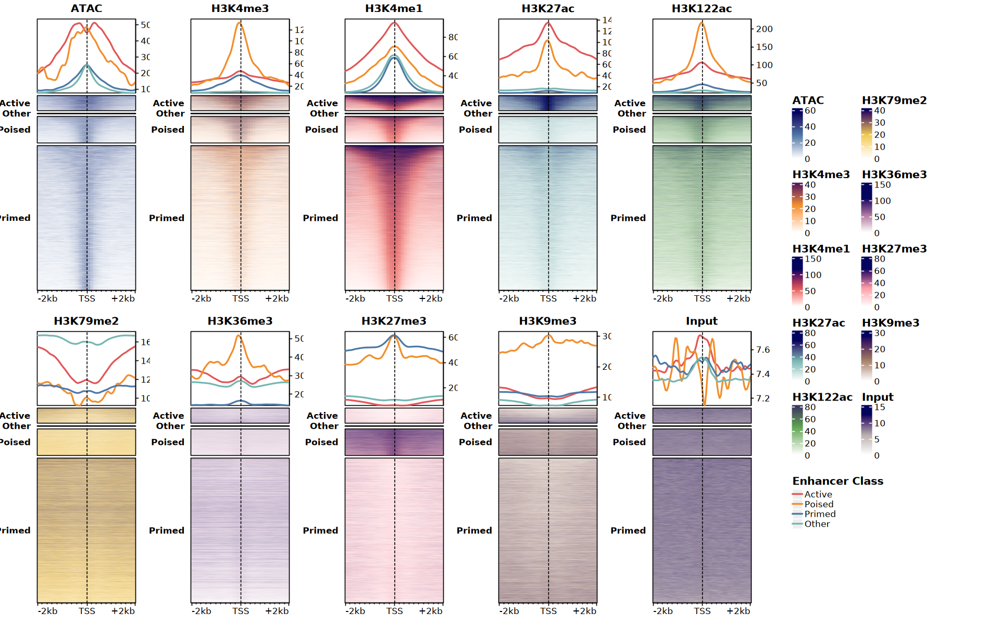

In [109]:
options(repr.plot.width = 16, repr.plot.height = 10)

# Create a new blank canvas
grid.newpage()
# Initialize a grid layout with 2 rows and 5 columns
pushViewport(viewport(layout = grid.layout(
    2, 6, widths = c(1, 1, 1, 1, 1, 1.5))))

for (i in seq_along(signals_enh_mat_list)) {
    mark_name <- names(signals_enh_mat_list)[i]

    # Enter the designated grid slot (viewport)
    row_idx <- if (i <= 5) 1 else 2
    col_idx <- if (i <= 5) i else i - 5
    pushViewport(viewport(layout.pos.row = row_idx, layout.pos.col = col_idx))
    
    # Construct the individual EnrichedHeatmap object
    ht <- EnrichedHeatmap(
        signals_enh_mat_list[[i]], 
        name = mark_name, 
        column_title = mark_name, 
        column_title_gp = gpar(fontsize = 12, fontface = "bold"),
        col = col_funs[[mark_name]], 
        top_annotation = HeatmapAnnotation(
            lines = anno_enriched(
                gp = gpar(lwd = 2, col = cluster_colors), 
                axis_param = list(gp = gpar(fontsize = 10))),
            height = unit(3, "cm"), show_legend = FALSE), 
        cluster_rows = FALSE,            
        row_order = unified_row_order_enh,   
        row_split = enhancer_clusters,
        row_title_rot = 0,
        row_title_gp = gpar(fontsize = 10, fontface = "bold"),
        axis_name = c("-2kb", "TSS", "+2kb"),
        axis_name_gp = gpar(fontsize = 10),
        show_heatmap_legend = FALSE, 
        show_row_names = FALSE,
        width = unit(4, "cm"),
        use_raster = TRUE)

    # Render the heatmap inside the current viewport
    draw(ht, newpage = FALSE)
    # Exit the current grid slot viewport
    popViewport()
}

pushViewport(viewport(layout.pos.row = 1:2, layout.pos.col = 6))
draw(
    packed_lgds, x = unit(0.1, "npc"), y = unit(0.5, "npc"), 
    just = c("left", "center"))
popViewport()

# Exit the main grid layout viewport
popViewport()

# 7. Super-enhancer

In [110]:
rose_df <- file.path(
    chipseq_dir, "11_superEnhancer", "mESC_LIF_H3K27ac", 
    "mESC_LIF_H3K27ac_SuperStitched.table.txt") |>
    read.delim(comment.char = "#")

head(rose_df)

,REGION_ID,CHROM,START,STOP,NUM_LOCI,CONSTITUENT_SIZE,mESC_LIF_H3K27ac.bam,mESC_LIF_Input.bam,stitchedPeakRank,isSuper
,<chr>,<chr>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<int>,<int>
1,35_mESC_LIF_H3K27ac_peak_5337_lociStitched,chr11,8513111,8672851,35,100984,338568.9,22475.418,1,1
2,1_mESC_LIF_H3K27ac_peak_18658_lociStitched,chr17,39843026,39848823,1,5798,394612.8,79341.220,2,1
3,12_mESC_LIF_H3K27ac_peak_9784_lociStitched,chr12,86454694,86522876,12,55166,235848.4,9293.207,3,1
4,16_mESC_LIF_H3K27ac_peak_30793_lociStitched,chr4,141267479,141338844,16,41787,195183.3,8870.669,4,1
5,14_mESC_LIF_H3K27ac_peak_9814_lociStitched,chr12,86866288,86941464,14,50673,192623.5,10291.594,5,1
6,13_mESC_LIF_H3K27ac_peak_22794_lociStitched,chr2,20631437,20694931,13,37671,181840.5,8755.823,6,1


In [111]:
rose_regions <- GRanges(
    seqnames = rose_df$CHROM,
    ranges = IRanges(start = rose_df$START, end = rose_df$STOP),
    strand = "*",
    ID = rose_df$REGION_ID,
    Rank = rose_df$stitchedPeakRank,
    Signal = rose_df$mESC_LIF_H3K27ac.bam - rose_df$mESC_LIF_Input.bam
)

In [112]:
# ~ 3 minutes
signals_se_mat_list <- lapply(
    signals_list, normalizeToMatrix, rose_regions, 
    value_column = "score", mean_mode = "w0", 
    extend = 2000, w = 20, k = 100, smooth = TRUE, 
    background = 0)

In [113]:
h3k27ac_mean <- rowMeans(signals_se_mat_list[["H3K27ac"]])
unified_row_order <- order(h3k27ac_mean, decreasing = TRUE)

base_colors <- ggthemes::tableau_color_pal("Tableau 10")(
    length(signals_se_mat_list)) |> 
    setNames(names(signals_se_mat_list))

col_funs <- lapply(names(signals_se_mat_list), function(mark) {
    max_val <- quantile(abs(signals_se_mat_list[[mark]]), 0.95, na.rm = TRUE)
    if(max_val == 0) max_val <- 1 
    circlize::colorRamp2(
        c(0, max_val/2, max_val), 
        c("#ffffff", base_colors[mark], "#03045e")
    )
})
names(col_funs) <- names(signals_se_mat_list)

In [114]:
lgd_list <- lapply(names(col_funs), function(mark) {
    Legend(
        col_fun = col_funs[[mark]], title = mark, 
        title_gp = gpar(fontsize = 10, fontface = "bold"),
        labels_gp = gpar(fontsize = 8), grid_width = unit(0.3, "cm")
    )
})

lgd_col1 <- packLegend(list = lgd_list[1:5], direction = "vertical")
lgd_col2 <- packLegend(list = lgd_list[6:10], direction = "vertical")
packed_lgds <- packLegend(lgd_col1, lgd_col2, direction = "horizontal", gap = unit(0.6, "cm"))

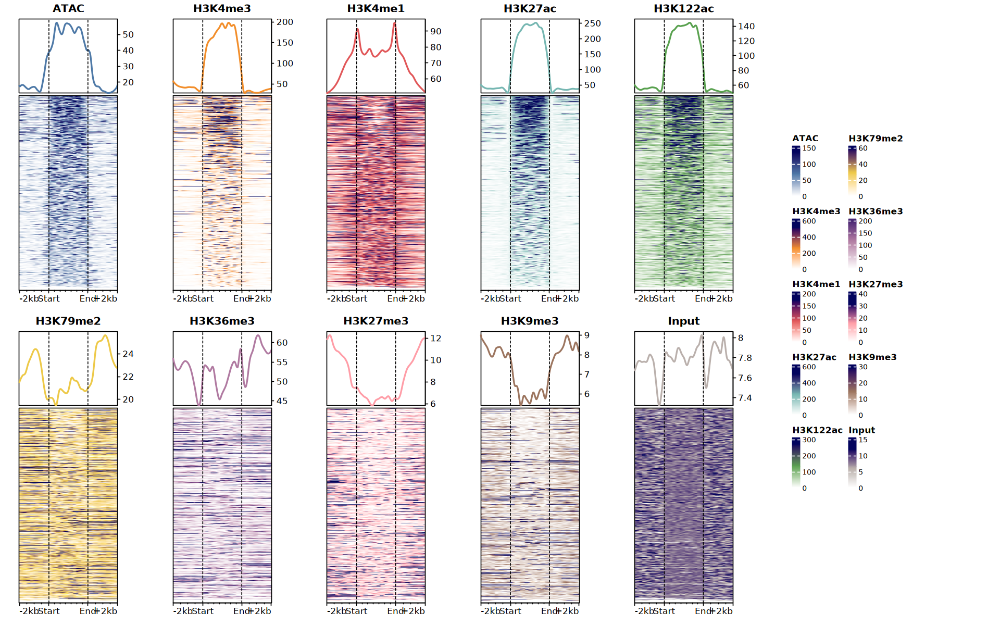

In [115]:
options(repr.plot.width = 16, repr.plot.height = 10)

# Create a new blank canvas
grid.newpage()
# Initialize a grid layout with 2 rows and 5 columns
pushViewport(viewport(layout = grid.layout(
    2, 6, widths = c(1, 1, 1, 1, 1, 1.5))))

for (i in seq_along(signals_se_mat_list)) {
    mark_name <- names(signals_se_mat_list)[i]

    # Enter the designated grid slot (viewport)
    row_idx <- if (i <= 5) 1 else 2
    col_idx <- if (i <= 5) i else i - 5
    pushViewport(viewport(layout.pos.row = row_idx, layout.pos.col = col_idx))
    
    # Construct the individual EnrichedHeatmap object
    ht <- EnrichedHeatmap(
        signals_se_mat_list[[i]], 
        name = mark_name, 
        column_title = mark_name, 
        column_title_gp = gpar(fontsize = 12, fontface = "bold"),
        col = col_funs[[mark_name]], 
        top_annotation = HeatmapAnnotation(
            lines = anno_enriched(
                gp = gpar(lwd = 2, col = base_colors[mark_name]), 
                axis_param = list(gp = gpar(fontsize = 10))),
            height = unit(3, "cm"), show_legend = FALSE), 
        cluster_rows = FALSE,            
        row_order = unified_row_order,
        axis_name = c("-2kb", "Start", "End", "+2kb"),
        axis_name_gp = gpar(fontsize = 10),
        show_heatmap_legend = FALSE, 
        show_row_names = FALSE,
        width = unit(4, "cm"),
        use_raster = TRUE)

    # Render the heatmap inside the current viewport
    draw(ht, newpage = FALSE)
    # Exit the current grid slot viewport
    popViewport()
}

pushViewport(viewport(layout.pos.row = 1:2, layout.pos.col = 6))
draw(
    packed_lgds, x = unit(0.1, "npc"), y = unit(0.5, "npc"), 
    just = c("left", "center"))
popViewport()

# Exit the main grid layout viewport
popViewport()